In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TRAIN_CSV = (
    PROJECT_ROOT
    / "Dataset/GOES_Preprocessed_200_320/train_triplets_preprocessed.csv"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "Dataset/GOES_TrainPatches_2048_NEW"
)

# Patch configuration
PATCH_SIZE = 2048
STRIDE = 2048
MIN_VALID_RATIO = 0.95

# Load training triplets
df = pd.read_csv(TRAIN_CSV)

print("Training triplets:", len(df))
print("CSV columns:", df.columns.tolist())
print(df.head(1).to_string(index=False))

Training triplets: 1014
CSV columns: ['input_0', 'target', 'input_2', 'mask_0', 'mask_target', 'mask_2', 'time_0', 'time_1', 'time_2']
                                                                                                                                                                           input_0                                                                                                                                                                             target                                                                                                                                                                            input_2                                                                                                                                                                            mask_0                                                                                                                                                       

In [3]:

for folder in [
    "img0",
    "gt",
    "img2",
    "mask0",
    "mask_gt",
    "mask2",
]:
    (OUTPUT_ROOT / folder).mkdir(parents=True, exist_ok=True)

def get_patch_positions(length, patch_size=2048, stride=2048):
    if length < patch_size:
        return []

    positions = list(range(0, length - patch_size + 1, stride))
    last_position = length - patch_size

    if positions[-1] != last_position:
        positions.append(last_position)

    return positions

print("Patch size:", PATCH_SIZE)
print("Stride:", STRIDE)
print("Minimum valid ratio:", MIN_VALID_RATIO)

# Example for a 5424 x 5424 image
print("Example positions:",
      get_patch_positions(5424, PATCH_SIZE, STRIDE))

Patch size: 2048
Stride: 2048
Minimum valid ratio: 0.95
Example positions: [0, 2048, 3376]


In [4]:

from tqdm.auto import tqdm

required_columns = [
    "input_0", "target", "input_2",
    "mask_0", "mask_target", "mask_2"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(
        f"Missing CSV columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

def load_array(path):
    path = Path(str(path))
    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path}")
    return np.load(path, mmap_mode="r")

def spatial_shape(arr):
    """Return height and width for 2D, HWC, or CHW arrays."""
    if arr.ndim == 2:
        return arr.shape

    if arr.ndim == 3:
        # Channel-first arrays, e.g. (3, H, W)
        if arr.shape[0] <= 4 and arr.shape[1] > 4:
            return arr.shape[1], arr.shape[2]

        # Channel-last arrays, e.g. (H, W, 3)
        if arr.shape[-1] <= 4:
            return arr.shape[0], arr.shape[1]

    raise ValueError(f"Unsupported array shape: {arr.shape}")

def crop_spatial(arr, y, x, size):
    if arr.ndim == 2:
        return np.asarray(arr[y:y+size, x:x+size])

    if arr.ndim == 3:
        if arr.shape[0] <= 4 and arr.shape[1] > 4:
            return np.asarray(arr[:, y:y+size, x:x+size])

        if arr.shape[-1] <= 4:
            return np.asarray(arr[y:y+size, x:x+size, :])

    raise ValueError(f"Unsupported array shape: {arr.shape}")

def load_mask(path):
    mask = np.asarray(load_array(path))
    mask = np.squeeze(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"Expected 2D validity mask, got {mask.shape}: {path}"
        )

    return mask

patch_records = []
patch_counter = 0
skipped_triplets = 0
skipped_patches = 0

for row_idx, row in tqdm(
    df.iterrows(), total=len(df), desc="Extracting 2048 patches"
):
    # Load matching frames
    img0 = load_array(row["input_0"])
    gt   = load_array(row["target"])
    img2 = load_array(row["input_2"])

    # Load validity masks
    mask0 = load_mask(row["mask_0"])
    mask_gt = load_mask(row["mask_target"])
    mask2 = load_mask(row["mask_2"])

    # Verify matching spatial dimensions
    shapes = [
        spatial_shape(img0),
        spatial_shape(gt),
        spatial_shape(img2),
        mask0.shape,
        mask_gt.shape,
        mask2.shape,
    ]

    if len(set(shapes)) != 1:
        raise ValueError(
            f"Spatial shape mismatch in triplet {row_idx}: {shapes}"
        )

    height, width = shapes[0]

    ys = get_patch_positions(height, PATCH_SIZE, STRIDE)
    xs = get_patch_positions(width, PATCH_SIZE, STRIDE)

    if not ys or not xs:
        skipped_triplets += 1
        continue

    for y in ys:
        for x in xs:
            # Crop all masks at identical coordinates
            m0 = mask0[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            mg = mask_gt[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            m2 = mask2[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

            # Skip patches with insufficient valid pixels
            ratios = (
                np.mean(m0 > 0),
                np.mean(mg > 0),
                np.mean(m2 > 0),
            )

            if min(ratios) < MIN_VALID_RATIO:
                skipped_patches += 1
                continue

            # Crop corresponding input and target patches
            p0 = crop_spatial(img0, y, x, PATCH_SIZE)
            pg = crop_spatial(gt, y, x, PATCH_SIZE)
            p2 = crop_spatial(img2, y, x, PATCH_SIZE)

            # Reject non-finite image data
            if not (
                np.isfinite(p0).all()
                and np.isfinite(pg).all()
                and np.isfinite(p2).all()
            ):
                skipped_patches += 1
                continue

            patch_id = f"patch_{patch_counter:07d}"

            # Save image patches
            paths = {
                "img0_path": OUTPUT_ROOT / "img0" / f"{patch_id}.npy",
                "gt_path": OUTPUT_ROOT / "gt" / f"{patch_id}.npy",
                "img2_path": OUTPUT_ROOT / "img2" / f"{patch_id}.npy",
                "mask0_path": OUTPUT_ROOT / "mask0" / f"{patch_id}.npy",
                "mask_gt_path": OUTPUT_ROOT / "mask_gt" / f"{patch_id}.npy",
                "mask2_path": OUTPUT_ROOT / "mask2" / f"{patch_id}.npy",
            }

            np.save(paths["img0_path"], p0.astype(np.float16))
            np.save(paths["gt_path"], pg.astype(np.float16))
            np.save(paths["img2_path"], p2.astype(np.float16))

            np.save(paths["mask0_path"], (m0 > 0).astype(np.uint8))
            np.save(paths["mask_gt_path"], (mg > 0).astype(np.uint8))
            np.save(paths["mask2_path"], (m2 > 0).astype(np.uint8))

            patch_records.append({
                "patch_id": patch_id,
                **{k: str(v) for k, v in paths.items()},
                "source_triplet_index": int(row_idx),
                "y": int(y),
                "x": int(x),
                "valid_ratio_img0": float(ratios[0]),
                "valid_ratio_gt": float(ratios[1]),
                "valid_ratio_img2": float(ratios[2]),
            })

            patch_counter += 1

# Save the patch manifest
patch_df = pd.DataFrame(patch_records)
manifest_path = OUTPUT_ROOT / "train_patches.csv"
patch_df.to_csv(manifest_path, index=False)

print("\nPATCH EXTRACTION COMPLETE")
print("Saved patches:", len(patch_df))
print("Skipped triplets too small:", skipped_triplets)
print("Skipped invalid/non-finite patches:", skipped_patches)
print("Manifest:", manifest_path)
print("Output directory:", OUTPUT_ROOT)

Extracting 2048 patches:   0%|          | 0/1014 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [4]:

print("Total saved patches:", len(patch_df))

if len(patch_df) > 0:
    sample = patch_df.iloc[0]

    for col in ["img0_path", "gt_path", "img2_path"]:
        arr = np.load(sample[col])
        print(
            col,
            "| shape:", arr.shape,
            "| dtype:", arr.dtype,
            "| range:", float(np.nanmin(arr)), float(np.nanmax(arr))
        )

    print("\nPatch manifest preview:")
    display(patch_df.head())

    assert len(patch_df) > 0
    print("Verification passed.")
else:
    print("No patches were saved. Check the validity masks and CSV paths.")

Total saved patches: 5067
img0_path | shape: (2048, 2048) | dtype: float16 | range: 0.0 0.8583984375
gt_path | shape: (2048, 2048) | dtype: float16 | range: 0.0 0.841796875
img2_path | shape: (2048, 2048) | dtype: float16 | range: 0.0 0.82177734375

Patch manifest preview:


,patch_id,img0_path,gt_path,img2_path,mask0_path,mask_gt_path,mask2_path,source_triplet_index,y,x,valid_ratio_img0,valid_ratio_gt,valid_ratio_img2
0,patch_0000000,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,0,2048,0.95104,0.95104,0.951001
1,patch_0000001,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,0,0.95497,0.95497,0.954970
2,patch_0000002,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,2048,1.00000,1.00000,1.000000
3,patch_0000003,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,3376,0.95497,0.95497,0.954970
4,patch_0000004,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,3376,2048,0.95104,0.95104,0.951040


Verification passed.


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd

PATCH_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "Dataset/GOES_TrainPatches_2048_NEW"
)

MANIFEST = PATCH_DIR / "train_patches.csv"
patch_df = pd.read_csv(MANIFEST)

image_cols = ["img0_path", "gt_path", "img2_path"]
mask_cols = ["mask0_path", "mask_gt_path", "mask2_path"]
all_cols = image_cols + mask_cols

missing_files = []
bad_shapes = []
nonfinite_images = []
bad_masks = []

for _, row in patch_df.iterrows():
    patch_id = row["patch_id"]

    # Check all six files exist
    for col in all_cols:
        if not Path(row[col]).is_file():
            missing_files.append((patch_id, col))

    if any(not Path(row[col]).is_file() for col in all_cols):
        continue

    # Check image patches
    for col in image_cols:
        arr = np.load(row[col], mmap_mode="r")

        if arr.shape != (2048, 2048):
            bad_shapes.append((patch_id, col, arr.shape))

        if not np.isfinite(arr).all():
            nonfinite_images.append((patch_id, col))

    # Check masks
    for col in mask_cols:
        mask = np.load(row[col], mmap_mode="r")

        if mask.shape != (2048, 2048):
            bad_shapes.append((patch_id, col, mask.shape))

        if not np.isfinite(mask).all():
            bad_masks.append((patch_id, col, "non-finite"))
        elif not np.isin(mask, [0, 1]).all():
            bad_masks.append((patch_id, col, "values outside 0/1"))

print("Total manifest entries:", len(patch_df))
print("Missing files:", len(missing_files))
print("Incorrect shapes:", len(bad_shapes))
print("Non-finite image patches:", len(nonfinite_images))
print("Invalid masks:", len(bad_masks))

assert len(patch_df) > 0
assert not missing_files, missing_files[:5]
assert not bad_shapes, bad_shapes[:5]
assert not nonfinite_images, nonfinite_images[:5]
assert not bad_masks, bad_masks[:5]

print("\nAll patch files passed validation.")

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATA_DIR = PROJECT_DIR / "Dataset" / "GOES_Preprocessed_200_320"

TRAIN_CSV = DATA_DIR / "train_triplets_preprocessed.csv"
TEST_CSV  = DATA_DIR / "test_triplets_preprocessed.csv"

PATCH_CSV = (
    PROJECT_DIR / "Dataset" / "GOES_TrainPatches_2048_NEW"
    / "train_patches.csv"
)

for path in [TRAIN_CSV, TEST_CSV, PATCH_CSV]:
    print(path, "| exists:", path.is_file())

assert TRAIN_CSV.is_file(), f"Training CSV not found: {TRAIN_CSV}"
assert TEST_CSV.is_file(), f"Testing CSV not found: {TEST_CSV}"
assert PATCH_CSV.is_file(), f"Patch manifest not found: {PATCH_CSV}"

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
patch_df = pd.read_csv(PATCH_CSV)

print("\nTraining triplets:", len(train_df))
print("Testing triplets:", len(test_df))
print("Training patches:", len(patch_df))

print("\nTraining CSV columns:", train_df.columns.tolist())
print("Testing CSV columns:", test_df.columns.tolist())
print("Patch manifest columns:", patch_df.columns.tolist())

In [ ]:
from pathlib import Path
import os

FRAME_COLS = ["input_0", "target", "input_2"]

for col in FRAME_COLS:
    assert col in train_df.columns, f"Missing column in train CSV: {col}"
    assert col in test_df.columns, f"Missing column in test CSV: {col}"

def frame_keys(df):
    keys = set()

    for col in FRAME_COLS:
        for value in df[col].dropna():
            p = Path(str(value))
            keys.add(("name", p.name))
            keys.add(("path", os.path.normcase(os.path.abspath(str(p)))))

    return keys

train_frames = frame_keys(train_df)
test_frames = frame_keys(test_df)

overlap = train_frames & test_frames

print("Unique training frame keys:", len(train_frames))
print("Unique testing frame keys:", len(test_frames))
print("Overlapping frame keys:", len(overlap))

if overlap:
    print("\nERROR: Train/test frame overlap detected.")
    for item in list(overlap)[:20]:
        print(item)
    raise AssertionError("Data leakage risk: frames overlap between train and test.")

print("\nPASS: No matching frame paths or filenames between train and test.")

In [ ]:
assert "source_triplet_index" in patch_df.columns, (
    "The patch manifest needs source_triplet_index to verify patch provenance."
)

source_indices = pd.to_numeric(
    patch_df["source_triplet_index"], errors="coerce"
)

assert source_indices.notna().all(), "Invalid source triplet indices found."

source_indices = source_indices.astype(int)

invalid_indices = source_indices[
    (source_indices < 0) | (source_indices >= len(train_df))
]

print("Patches in manifest:", len(patch_df))
print("Unique source training triplets:", source_indices.nunique())
print("Invalid source indices:", len(invalid_indices))

assert len(invalid_indices) == 0, (
    "Some patches reference triplet indices outside the training CSV."
)

print("\nPASS: All patches refer to valid rows of the training CSV.")

In [9]:
required_cols = [
    "patch_id",
    "source_triplet_index",
    "img0_path",
    "gt_path",
    "img2_path",
]

missing_cols = [c for c in required_cols if c not in patch_df.columns]
assert not missing_cols, f"Missing manifest columns: {missing_cols}"

def canonical_path(value):
    return os.path.normcase(os.path.abspath(str(value)))

# Compare saved patch provenance against the training CSV.
# Patch paths are cropped .npy files, so compare the recorded index to
# the source-triplet row and report the source frames for inspection.
sample_n = min(10, len(patch_df))

for _, patch in patch_df.head(sample_n).iterrows():
    idx = int(patch["source_triplet_index"])
    source = train_df.iloc[idx]

    print(f"\nPatch: {patch['patch_id']} | source triplet row: {idx}")
    print("  source img0:", source["input_0"])
    print("  source gt:  ", source["target"])
    print("  source img2:", source["input_2"])

print("\nSample provenance inspection complete.")


Patch: patch_0000000 | source triplet row: 0
  source img0: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train/images/OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.npy
  source gt:   /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train/images/OR_ABI-L1b-RadF-M6C13_G19_s20261880010202_e20261880019522_c20261880019564.npy
  source img2: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train/images/OR_ABI-L1b-RadF-M6C13_G19_s20261880020202_e20261880029522_c20261880029572.npy

Patch: patch_0000001 | source triplet row: 0
  source img0: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train/images/OR_ABI-L1b-RadF-M6C13_G19_s20261880000202_e20261880009522_c20261880009576.npy
  source gt:   /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_Preprocessed_200_320/train/images/OR_ABI-L1b-RadF-

In [10]:
print("=" * 55)
print("GOES DATA SPLIT AUDIT")
print("=" * 55)

print(f"Training triplets : {len(train_df):,}")
print(f"Testing triplets  : {len(test_df):,}")
print(f"Training patches  : {len(patch_df):,}")
print(f"Unique train sources represented by patches: {source_indices.nunique():,}")
print(f"Train/test frame overlap: {len(overlap)}")

assert len(train_df) > 0
assert len(test_df) > 0
assert len(patch_df) > 0
assert len(overlap) == 0
assert len(invalid_indices) == 0

print("\nPASS: Basic train/test isolation checks completed.")

GOES DATA SPLIT AUDIT
Training triplets : 1,014
Testing triplets  : 253
Training patches  : 5,067
Unique train sources represented by patches: 1,014
Train/test frame overlap: 0

PASS: Basic train/test isolation checks completed.


In [1]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

PATCH_DIR = (
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "Dataset/GOES_TrainPatches_2048_NEW"
)

MANIFEST = os.path.join(PATCH_DIR, "train_patches.csv")
patch_df = pd.read_csv(MANIFEST)

print("Total patches:", len(patch_df))
print("Manifest columns:", patch_df.columns.tolist())

class GOESPatchDataset(Dataset):
    def __init__(self, dataframe, patch_size=2048):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size

    def __len__(self):
        return len(self.df)

    def load_image(self, path):
        arr = np.load(path).astype(np.float32)

        if arr.shape != (self.patch_size, self.patch_size):
            raise ValueError(
                f"Unexpected image shape {arr.shape}: {path}"
            )

        if not np.isfinite(arr).all():
            raise ValueError(f"Non-finite image values: {path}")

        # GOES data is grayscale. RIFE expects 3 channels per frame.
        tensor = torch.from_numpy(arr).unsqueeze(0)
        tensor = tensor.repeat(3, 1, 1)

        return tensor.contiguous()

    def load_mask(self, path):
        arr = np.load(path).astype(np.float32)

        if arr.shape != (self.patch_size, self.patch_size):
            raise ValueError(
                f"Unexpected mask shape {arr.shape}: {path}"
            )

        return torch.from_numpy(arr).unsqueeze(0).contiguous()

    def __getitem__(self, index):
        row = self.df.iloc[index]

        img0 = self.load_image(row["img0_path"])
        gt = self.load_image(row["gt_path"])
        img2 = self.load_image(row["img2_path"])

        mask0 = self.load_mask(row["mask0_path"])
        mask_gt = self.load_mask(row["mask_gt_path"])
        mask2 = self.load_mask(row["mask2_path"])

        return {
            "img0": img0,
            "gt": gt,
            "img2": img2,
            "mask0": mask0,
            "mask_gt": mask_gt,
            "mask2": mask2,
            "patch_id": row["patch_id"],
        }

train_dataset = GOESPatchDataset(patch_df, patch_size=2048)

print("Dataset created successfully.")
print("Dataset length:", len(train_dataset))

Total patches: 5067
Manifest columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
Dataset created successfully.
Dataset length: 5067


In [2]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("DataLoader created.")
print("Number of batches per epoch:", len(train_loader))

# Load one batch for testing
batch = next(iter(train_loader))

print("\nBatch verification:")
for key in ["img0", "gt", "img2", "mask0", "mask_gt", "mask2"]:
    print(
        f"{key:10s}",
        "shape =", tuple(batch[key].shape),
        "dtype =", batch[key].dtype
    )

# RIFE input: concatenate first and third frames
imgs = torch.cat(
    [batch["img0"], batch["img2"]],
    dim=1
)

gt = batch["gt"]

print("\nRIFE input shape:", tuple(imgs.shape))
print("Ground-truth shape:", tuple(gt.shape))

assert imgs.shape == (1, 6, 2048, 2048)
assert gt.shape == (1, 3, 2048, 2048)

print("\nBatch verification passed.")

DataLoader created.
Number of batches per epoch: 5067

Batch verification:
img0       shape = (1, 3, 2048, 2048) dtype = torch.float32
gt         shape = (1, 3, 2048, 2048) dtype = torch.float32
img2       shape = (1, 3, 2048, 2048) dtype = torch.float32
mask0      shape = (1, 1, 2048, 2048) dtype = torch.float32
mask_gt    shape = (1, 1, 2048, 2048) dtype = torch.float32
mask2      shape = (1, 1, 2048, 2048) dtype = torch.float32

RIFE input shape: (1, 6, 2048, 2048)
Ground-truth shape: (1, 3, 2048, 2048)

Batch verification passed.


In [3]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("CUDA is unavailable. Do not start GPU training yet.")

PyTorch version: 2.13.0+cu130
CUDA available: True
GPU: NVIDIA H200 NVL
GPU memory: 139.8 GB


In [14]:
from pathlib import Path
import ast

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

matches = []

for py_file in PROJECT_DIR.rglob("*.py"):
    # Ignore common large or irrelevant directories
    if any(part in {
        ".git", "__pycache__", "venv", ".venv"
    } for part in py_file.parts):
        continue

    try:
        source = py_file.read_text(
            encoding="utf-8",
            errors="ignore"
        )
        tree = ast.parse(source)
    except Exception:
        continue

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name == "update":
                matches.append((str(py_file), node.lineno))

print("Files containing an update() method:\n")

for file_path, line_no in matches:
    print(f"{file_path}  (line {line_no})")

if not matches:
    print(
        "\nNo update() method found. We need to inspect your RIFE "
        "training files before writing the training loop."
    )

Files containing an update() method:

/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM.py  (line 143)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py  (line 72)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/oldmodel/RIFE_HD.py  (line 215)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/oldmodel/RIFE_HDv2.py  (line 200)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE_CMAM_CMCL-checkpoint.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE-checkpoint.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE_CMAM-checkpoint.py  (line 143)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Official_RIFE/

In [15]:
from pathlib import Path
import ast

RIFE_FILE = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "Official_RIFE/model/RIFE.py"
)

assert RIFE_FILE.exists(), f"Base RIFE file not found: {RIFE_FILE}"

source = RIFE_FILE.read_text(encoding="utf-8", errors="ignore")
lines = source.splitlines()
tree = ast.parse(source)

print("BASE RIFE FILE:", RIFE_FILE)

for node in ast.walk(tree):
    if not isinstance(node, ast.ClassDef):
        continue

    methods = {
        item.name: item
        for item in node.body
        if isinstance(item, (ast.FunctionDef, ast.AsyncFunctionDef))
    }

    if not methods:
        continue

    print("\n" + "=" * 70)
    print("CLASS:", node.name)
    print("METHODS:", list(methods.keys()))

    for method_name in [
        "__init__", "update", "train", "save_model", "load_model"
    ]:
        method = methods.get(method_name)

        if method is None:
            continue

        print(f"\n--- {node.name}.{method_name} ---")

        for i in range(method.lineno - 1, method.end_lineno):
            print(f"{i + 1:4d}: {lines[i]}")

BASE RIFE FILE: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Official_RIFE/model/RIFE.py

CLASS: Model
METHODS: ['__init__', 'train', 'eval', 'device', 'load_model', 'save_model', 'inference', 'update']

--- Model.__init__ ---
  19:     def __init__(self, local_rank=-1, arbitrary=False):
  20:         if arbitrary == True:
  21:             self.flownet = IFNet_m()
  22:         else:
  23:             self.flownet = IFNet()
  24:         self.device()
  25:         self.optimG = AdamW(self.flownet.parameters(), lr=1e-6, weight_decay=1e-3) # use large weight decay may avoid NaN loss
  26:         self.epe = EPE()
  27:         self.lap = LapLoss()
  28:         self.sobel = SOBEL()
  29:         if local_rank != -1:
  30:             self.flownet = DDP(self.flownet, device_ids=[local_rank], output_device=local_rank)

--- Model.update ---
  69:     def update(self, imgs, gt, learning_rate=0, mul=1, training=True, flow_gt=None):
  70:         for param_group in self.optimG.param

In [17]:
import torch
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

PATCH_DIR = PROJECT_DIR / "Dataset" / "GOES_TrainPatches_2048_NEW"
MANIFEST = PATCH_DIR / "train_patches.csv"

patch_df = pd.read_csv(MANIFEST)

assert len(patch_df) == 5067, (
    f"Expected 5067 patches, found {len(patch_df)}"
)

assert torch.cuda.is_available(), "CUDA is not available."

print("Model: Base RIFE")
print("Training patches:", len(patch_df))
print("Patch size: 2048 × 2048")
print("Batch size: 1")
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)
print("Checkpoint directory:", PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048")

Model: Base RIFE
Training patches: 5067
Patch size: 2048 × 2048
Batch size: 1
GPU: NVIDIA H200 NVL
CUDA: 13.0
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048


In [ ]:
import os
import sys
import csv
import time
from pathlib import Path

import torch
import pandas as pd
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"
CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
SAVE_EVERY_EPOCH = 1
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

assert torch.cuda.is_available(), "CUDA GPU is unavailable."
assert len(train_dataset) > 0, "Training dataset is empty."

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Checkpoint directory:", CHECKPOINT_DIR)

# ============================================================
# 2. IMPORT BASE RIFE
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

# Create a fresh model unless an epoch checkpoint is available.
# The earlier smoke-test checkpoint is intentionally not loaded.
rife_model = Model()

# ============================================================
# 3. CHECK FOR AN EPOCH CHECKPOINT TO RESUME
# ============================================================

def checkpoint_epoch(path):
    # Expected filename: epoch_001.pth, epoch_002.pth, ...
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1

epoch_checkpoints = sorted(
    CHECKPOINT_DIR.glob("epoch_*.pth"),
    key=checkpoint_epoch
)

start_epoch = 0

if epoch_checkpoints:
    resume_path = epoch_checkpoints[-1]
    print("\nResuming from:", resume_path)

    checkpoint = torch.load(
        resume_path,
        map_location=device,
        weights_only=False
    )

    rife_model.flownet.load_state_dict(
        checkpoint["model_state_dict"]
    )
    rife_model.optimG.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = int(checkpoint["completed_epochs"])

    print("Completed epochs:", start_epoch)
else:
    print("\nNo epoch checkpoint found.")
    print("Starting base RIFE with fresh weights.")

if start_epoch >= EPOCHS:
    print(
        f"Training already reached {start_epoch} epochs. "
        "Increase EPOCHS if you want to continue training."
    )
else:
    print("Next epoch:", start_epoch + 1)

# ============================================================
# 4. LOGGING HELPERS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)

def append_csv(path, row):
    file_exists = path.exists()

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)

def save_epoch_checkpoint(epoch_number, epoch_stats):
    checkpoint_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )

    torch.save(
        {
            "model_state_dict": rife_model.flownet.state_dict(),
            "optimizer_state_dict": rife_model.optimG.state_dict(),
            "completed_epochs": epoch_number,
            "learning_rate": LEARNING_RATE,
            "patch_size": 2048,
            "training_patches": len(train_dataset),
            "epoch_stats": epoch_stats,
        },
        checkpoint_path
    )

    print("Checkpoint saved:", checkpoint_path)

# ============================================================
# 5. FULL EPOCH-BASED TRAINING
# ============================================================

if start_epoch < EPOCHS:

    for epoch_idx in range(start_epoch, EPOCHS):
        epoch_number = epoch_idx + 1
        epoch_start_time = time.time()

        rife_model.train()

        sum_l1 = 0.0
        sum_teacher = 0.0
        sum_distill = 0.0
        sum_total = 0.0
        successful_batches = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch_number}/{EPOCHS}",
            leave=True
        )

        for batch_idx, batch in enumerate(progress, start=1):

            # Each image: [B, 3, 2048, 2048]
            img0 = batch["img0"].to(device, non_blocking=True)
            gt = batch["gt"].to(device, non_blocking=True)
            img2 = batch["img2"].to(device, non_blocking=True)

            # RIFE input: [B, 6, H, W]
            imgs = torch.cat([img0, img2], dim=1)

            # Base RIFE update performs forward, loss calculation,
            # backward propagation, and optimizer step.
            _, info = rife_model.update(
                imgs,
                gt,
                learning_rate=LEARNING_RATE,
                training=True
            )

            loss_l1 = scalar(info["loss_l1"])
            loss_teacher = scalar(info["loss_tea"])
            loss_distill = scalar(info["loss_distill"])

            # This is the objective used inside the official wrapper.
            total_loss = (
                loss_l1
                + loss_teacher
                + 0.01 * loss_distill
            )

            if not all(
                torch.isfinite(torch.tensor(v)).item()
                for v in [
                    loss_l1, loss_teacher,
                    loss_distill, total_loss
                ]
            ):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch_number}, "
                    f"batch {batch_idx}. Stop and inspect the data/model."
                )

            sum_l1 += loss_l1
            sum_teacher += loss_teacher
            sum_distill += loss_distill
            sum_total += total_loss
            successful_batches += 1

            progress.set_postfix(
                l1=f"{loss_l1:.5f}",
                teacher=f"{loss_teacher:.5f}",
                distill=f"{loss_distill:.5f}",
                total=f"{total_loss:.5f}"
            )

            # Record periodic batch-level losses
            if (
                batch_idx % LOG_EVERY_BATCHES == 0
                or batch_idx == len(train_loader)
            ):
                append_csv(
                    BATCH_LOG,
                    {
                        "epoch": epoch_number,
                        "batch": batch_idx,
                        "loss_l1": loss_l1,
                        "loss_teacher": loss_teacher,
                        "loss_distill": loss_distill,
                        "total_loss": total_loss,
                    }
                )

            del img0, gt, img2, imgs

        # ----------------------------------------------------
        # End-of-epoch averages
        # ----------------------------------------------------

        if successful_batches == 0:
            raise RuntimeError(
                f"No successful batches in epoch {epoch_number}"
            )

        epoch_stats = {
            "epoch": epoch_number,
            "batches": successful_batches,
            "avg_loss_l1": sum_l1 / successful_batches,
            "avg_loss_teacher": sum_teacher / successful_batches,
            "avg_loss_distill": sum_distill / successful_batches,
            "avg_total_loss": sum_total / successful_batches,
            "epoch_seconds": time.time() - epoch_start_time,
        }

        append_csv(EPOCH_LOG, epoch_stats)

        print("\nEpoch summary")
        print("-" * 55)
        for key, value in epoch_stats.items():
            print(f"{key}: {value}")

        # ----------------------------------------------------
        # Save checkpoint after every completed epoch
        # ----------------------------------------------------

        if epoch_number % SAVE_EVERY_EPOCH == 0:
            save_epoch_checkpoint(epoch_number, epoch_stats)

        print("Epoch loss log:", EPOCH_LOG)
        print("Batch loss log:", BATCH_LOG)

    print("\nBASE RIFE TRAINING FINISHED.")

else:
    print("No additional epochs required.")

GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067
Epochs: 100
Learning rate: 1e-06
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048

No epoch checkpoint found.
Starting base RIFE with fresh weights.
Next epoch: 1


Epoch 1/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch summary
-------------------------------------------------------
epoch: 1
batches: 5067
avg_loss_l1: 0.020917282195863626
avg_loss_teacher: 0.020556878733211763
avg_loss_distill: 0.007697757194126556
avg_total_loss: 0.04155113850101674
epoch_seconds: 4001.529649734497
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_001.pth
Epoch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 2/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch summary
-------------------------------------------------------
epoch: 2
batches: 5067
avg_loss_l1: 0.02005687147839896
avg_loss_teacher: 0.01998582900321111
avg_loss_distill: 0.007996547845197216
avg_total_loss: 0.04012266596006189
epoch_seconds: 3262.1472227573395
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_002.pth
Epoch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 3/100:   0%|          | 0/5067 [00:00<?, ?it/s]

... (17 outputs left out)


Epoch summary
-------------------------------------------------------
epoch: 11
batches: 5067
avg_loss_l1: 0.016040959628896234
avg_loss_teacher: 0.016203695461550996
avg_loss_distill: 0.029034443612452887
avg_total_loss: 0.0325349995265718
epoch_seconds: 2661.508772611618
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_011.pth
Epoch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 12/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch summary
-------------------------------------------------------
epoch: 12
batches: 5067
avg_loss_l1: 0.015953082431387874
avg_loss_teacher: 0.01611956943893294
avg_loss_distill: 0.03057274969205707
avg_total_loss: 0.03237837936724147
epoch_seconds: 2702.0347797870636
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_012.pth
Epoch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch loss log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 13/100:   0%|          | 0/5067 [00:00<?, ?it/s]

In [ ]:

import os
import sys
import csv
import time
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RESUME_PATH = CHECKPOINT_DIR / "epoch_012.pth"

EPOCHS = 100
LEARNING_RATE = 1e-6
LOG_EVERY_BATCHES = 50
SAVE_EVERY_EPOCH = 1

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY ENVIRONMENT
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Check your HPC GPU allocation."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

if not RESUME_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 12 checkpoint not found: {RESUME_PATH}"
    )

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3,
    2
), "GB")
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Target epochs:", EPOCHS)
print("Resume checkpoint:", RESUME_PATH)

# ============================================================
# 3. IMPORT OFFICIAL RIFE
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

# Initialize official model and optimizer.
rife_model = Model()

# ============================================================
# 4. RESTORE EPOCH 12 MODEL + OPTIMIZER
# ============================================================

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

# Retain the learning rate used by the previous training run.
saved_lr = checkpoint.get("learning_rate", LEARNING_RATE)

if start_epoch != 12:
    raise RuntimeError(
        f"Expected Epoch 12 checkpoint, got completed_epochs="
        f"{start_epoch}. Verify the checkpoint before training."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Checkpoint already completed {start_epoch} epochs."
    )

print("\nCheckpoint restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Saved learning rate:", saved_lr)

# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)


def append_csv(path, row):
    file_exists = path.exists()

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not file_exists or path.stat().st_size == 0:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, epoch_stats):
    checkpoint_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )

    temporary_path = CHECKPOINT_DIR / (
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict": rife_model.flownet.state_dict(),
        "optimizer_state_dict": rife_model.optimG.state_dict(),
        "completed_epochs": epoch_number,
        "learning_rate": saved_lr,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": epoch_stats,
    }

    # Write temporary file first to reduce risk of an incomplete
    # checkpoint if the process is interrupted during saving.
    torch.save(payload, temporary_path)
    os.replace(temporary_path, checkpoint_path)

    print("Checkpoint saved:", checkpoint_path)


# ============================================================
# 6. RESUME TRAINING FROM EPOCH 13
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start_time = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    # Plain tqdm avoids dependence on the notebook widget model.
    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )
        gt = batch["gt"].to(
            device, non_blocking=True
        )
        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # Official RIFE input: concatenate two RGB frames.
        imgs = torch.cat([img0, img2], dim=1)

        # Official wrapper performs forward, backward and
        # optimizer updates internally.
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=saved_lr,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        values = [
            loss_l1,
            loss_teacher,
            loss_distill,
            total_loss
        ]

        if not all(torch.isfinite(torch.tensor(v)).item()
                   for v in values):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_idx}. Check the data and model."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss
        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # --------------------------------------------------------
    # 7. EPOCH SUMMARY
    # --------------------------------------------------------

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    epoch_stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher": sum_teacher / successful_batches,
        "avg_loss_distill": sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start_time,
    }

    append_csv(EPOCH_LOG, epoch_stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in epoch_stats.items():
        print(f"{key}: {value}")

    # --------------------------------------------------------
    # 8. SAVE AFTER EVERY COMPLETED EPOCH
    # --------------------------------------------------------

    if epoch_number % SAVE_EVERY_EPOCH == 0:
        save_epoch_checkpoint(epoch_number, epoch_stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING FINISHED.")


GPU: NVIDIA H200 NVL
GPU memory: 139.8 GB
Training patches: 5067
Batches per epoch: 5067
Target epochs: 100
Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_012.pth

Checkpoint restored successfully.
Completed epochs: 12
Next epoch: 13
Saved learning rate: 1e-06


Epoch 13/100: 100%|██████████| 5067/5067 [59:10<00:00,  1.43it/s, distill=0.04439, l1=0.01526, teacher=0.01546, total=0.03116] 



COMPLETED EPOCH 13/100
epoch: 13
batches: 5067
avg_loss_l1: 0.015857811649415427
avg_loss_teacher: 0.01602731069679682
avg_loss_distill: 0.032481488367005554
avg_total_loss: 0.032209937229882295
epoch_seconds: 3550.5622220039368
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_013.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 14/100: 100%|██████████| 5067/5067 [1:05:01<00:00,  1.30it/s, distill=0.05073, l1=0.01761, teacher=0.01777, total=0.03588]



COMPLETED EPOCH 14/100
epoch: 14
batches: 5067
avg_loss_l1: 0.01575006538248842
avg_loss_teacher: 0.015922135510431347
avg_loss_distill: 0.03491395600680471
avg_total_loss: 0.032021340452987775
epoch_seconds: 3901.1116280555725
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_014.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 15/100: 100%|██████████| 5067/5067 [1:01:43<00:00,  1.37it/s, distill=0.04980, l1=0.01975, teacher=0.01988, total=0.04013]


... (6 outputs left out)


COMPLETED EPOCH 18/100
epoch: 18
batches: 5067
avg_loss_l1: 0.015341268199489905
avg_loss_teacher: 0.015520098316625645
avg_loss_distill: 0.04748934677423211
avg_total_loss: 0.03133625998385776
epoch_seconds: 2740.0095880031586
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_018.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 19/100: 100%|██████████| 5067/5067 [39:20<00:00,  2.15it/s, distill=0.07169, l1=0.02010, teacher=0.02033, total=0.04115]



COMPLETED EPOCH 19/100
epoch: 19
batches: 5067
avg_loss_l1: 0.01524105756108886
avg_loss_teacher: 0.015420880065931297
avg_loss_distill: 0.050662317689863304
avg_total_loss: 0.031168560803918798
epoch_seconds: 2360.1099331378937
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_019.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 20/100:   4%|▍         | 196/5067 [02:20<59:57,  1.35it/s, distill=0.05609, l1=0.01464, teacher=0.01485, total=0.03005]  

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun dataset preparation."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun DataLoader preparation."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. FIND THE LATEST COMPLETED EPOCH CHECKPOINT
# ============================================================

def checkpoint_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1


epoch_checkpoints = sorted(
    [
        p for p in CHECKPOINT_DIR.glob("epoch_*.pth")
        if checkpoint_epoch(p) >= 0
    ],
    key=checkpoint_epoch
)

if not epoch_checkpoints:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

RESUME_PATH = epoch_checkpoints[-1]

print("\nLatest checkpoint:", RESUME_PATH)

# ============================================================
# 4. IMPORT OFFICIAL RIFE AND RESTORE TRAINING STATE
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])
learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch >= EPOCHS:
    print(f"Training already completed {start_epoch} epochs.")
    raise SystemExit

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)


def append_csv(path, row):
    exists = path.exists() and path.stat().st_size > 0

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )
    temp_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict": rife_model.flownet.state_dict(),
        "optimizer_state_dict": rife_model.optimG.state_dict(),
        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )
        gt = batch["gt"].to(
            device, non_blocking=True
        )
        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # Official RIFE wrapper performs the training update.
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1 + loss_teacher + 0.01 * loss_distill
        )

        losses = [
            loss_l1, loss_teacher, loss_distill, total_loss
        ]

        if not all(math.isfinite(v) for v in losses):
            raise RuntimeError(
                f"Invalid loss at epoch {epoch_number}, "
                f"batch {batch_idx}. Check the model and data."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss
        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher": sum_teacher / successful_batches,
        "avg_loss_distill": sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save after every completed epoch.
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)


GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Latest checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_019.pth

Model and optimizer restored successfully.
Completed epochs: 19
Next epoch: 20
Target epoch: 100
Learning rate: 1e-06


Epoch 20/100: 100%|██████████| 5067/5067 [1:01:03<00:00,  1.38it/s, distill=0.07323, l1=0.01569, teacher=0.01591, total=0.03233]



COMPLETED EPOCH 20/100
epoch: 20
batches: 5067
avg_loss_l1: 0.015134682419347956
avg_loss_teacher: 0.015314847608991091
avg_loss_distill: 0.05404156693945728
avg_total_loss: 0.03098994569773368
epoch_seconds: 3663.3807532787323
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_020.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 21/100: 100%|██████████| 5067/5067 [37:10<00:00,  2.27it/s, distill=0.04588, l1=0.01470, teacher=0.01485, total=0.03001]



COMPLETED EPOCH 21/100
epoch: 21
batches: 5067
avg_loss_l1: 0.015047610726722874
avg_loss_teacher: 0.015228831231114731
avg_loss_distill: 0.057267764837611396
avg_total_loss: 0.030849119606213754
epoch_seconds: 2230.041344165802
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_021.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 22/100: 100%|██████████| 5067/5067 [38:22<00:00,  2.20it/s, distill=0.04402, l1=0.01382, teacher=0.01397, total=0.02823]


... (12 outputs left out)


COMPLETED EPOCH 29/100
epoch: 29
batches: 5067
avg_loss_l1: 0.014279404266909991
avg_loss_teacher: 0.01445017901282498
avg_loss_distill: 0.08926562632308901
avg_total_loss: 0.029622239542965955
epoch_seconds: 3714.49031662941
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_029.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 30/100:  65%|██████▍   | 3289/5067 [40:31<22:18,  1.33it/s, distill=0.05299, l1=0.00955, teacher=0.00971, total=0.01978]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Epoch 30/100: 100%|██████████| 5067/5067 [58:55<00:00,  1.43it/s, distill=0.10103, l1=0.01282, teacher=0.01305, total=0.02688]



COMPLETED EPOCH 30/100
epoch: 30
batches: 5067
avg_loss_l1: 0.01420981740755091
avg_loss_teacher: 0.014378120156656786
avg_loss_distill: 0.0919120703028555
avg_total_loss: 0.029507058267236288
epoch_seconds: 3535.28129196167
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_030.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 31/100:   2%|▏         | 122/5067 [01:12<1:03:02,  1.31it/s, distill=0.07589, l1=0.01173, teacher=0.01189, total=0.02438]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. CHECK GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to a GPU-enabled HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset missing. Rerun your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader missing. Rerun your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. FIND LATEST COMPLETED CHECKPOINT
# ============================================================

def checkpoint_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1


epoch_checkpoints = sorted(
    [
        p for p in CHECKPOINT_DIR.glob("epoch_*.pth")
        if checkpoint_epoch(p) >= 0
    ],
    key=checkpoint_epoch
)

if not epoch_checkpoints:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

RESUME_PATH = epoch_checkpoints[-1]

print("\nLatest checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

# This run is intended to resume at Epoch 31.
if start_epoch != 30:
    raise RuntimeError(
        f"Expected Epoch 30 checkpoint, but latest checkpoint "
        f"reports completed_epochs={start_epoch}. "
        f"Verify the checkpoint before proceeding."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)


def append_csv(path, row):
    file_exists = path.exists() and path.stat().st_size > 0

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict": rife_model.flownet.state_dict(),
        "optimizer_state_dict": rife_model.optimG.state_dict(),
        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. TRAIN FROM EPOCH 31 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )
        gt = batch["gt"].to(
            device, non_blocking=True
        )
        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # RIFE input: concatenate two RGB frames.
        imgs = torch.cat([img0, img2], dim=1)

        # Official RIFE update handles forward/backward/optimizer.
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1 + loss_teacher + 0.01 * loss_distill
        )

        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_idx}."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss
        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Save batch-level loss records every 50 batches.
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # --------------------------------------------------------
    # END-OF-EPOCH SUMMARY
    # --------------------------------------------------------

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher": sum_teacher / successful_batches,
        "avg_loss_distill": sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save every completed epoch.
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)


GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Latest checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_030.pth

Model and optimizer restored successfully.
Completed epochs: 30
Next epoch: 31
Target epoch: 100
Learning rate: 1e-06


Epoch 31/100: 100%|██████████| 5067/5067 [57:12<00:00,  1.48it/s, distill=0.12011, l1=0.01805, teacher=0.01826, total=0.03751]



COMPLETED EPOCH 31/100
epoch: 31
batches: 5067
avg_loss_l1: 0.014118019884953268
avg_loss_teacher: 0.014281015730115032
avg_loss_distill: 0.09448175772492269
avg_total_loss: 0.029343853192317585
epoch_seconds: 3432.247920513153
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_031.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 32/100: 100%|██████████| 5067/5067 [1:03:43<00:00,  1.33it/s, distill=0.06606, l1=0.01522, teacher=0.01534, total=0.03121]



COMPLETED EPOCH 32/100
epoch: 32
batches: 5067
avg_loss_l1: 0.014049720876352636
avg_loss_teacher: 0.014206768417900393
avg_loss_distill: 0.09672645431431719
avg_total_loss: 0.02922375383739618
epoch_seconds: 3823.4212534427643
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_032.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 33/100: 100%|██████████| 5067/5067 [1:12:23<00:00,  1.17it/s, distill=0.05527, l1=0.00928, teacher=0.00940, total=0.01923]


... (13 outputs left out)

Epoch 40/100: 100%|██████████| 5067/5067 [40:51<00:00,  2.07it/s, distill=0.15264, l1=0.01310, teacher=0.01310, total=0.02773]



COMPLETED EPOCH 40/100
epoch: 40
batches: 5067
avg_loss_l1: 0.013594282338131407
avg_loss_teacher: 0.01363287038457083
avg_loss_distill: 0.11288088009875978
avg_total_loss: 0.028355961523689858
epoch_seconds: 2451.3912761211395
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_040.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 41/100:  93%|█████████▎| 4693/5067 [35:32<02:49,  2.20it/s, distill=0.13349, l1=0.01577, teacher=0.01582, total=0.03293]


KeyboardInterrupt: 

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. FIND AND VALIDATE THE LATEST CHECKPOINT
# ============================================================

def checkpoint_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1


epoch_checkpoints = sorted(
    [
        p for p in CHECKPOINT_DIR.glob("epoch_*.pth")
        if checkpoint_epoch(p) >= 0
    ],
    key=checkpoint_epoch
)

if not epoch_checkpoints:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

RESUME_PATH = epoch_checkpoints[-1]

print("\nLatest checkpoint:", RESUME_PATH)

# ============================================================
# 4. RESTORE OFFICIAL RIFE MODEL AND OPTIMIZER
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

# Expected checkpoint is epoch_040.pth.
if start_epoch != 40:
    raise RuntimeError(
        f"Expected Epoch 40 checkpoint, but found "
        f"completed_epochs={start_epoch}. "
        "Check the latest checkpoint before proceeding."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING HELPERS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)


def append_csv(path, row):
    file_exists = path.exists() and path.stat().st_size > 0

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )
    temp_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict": rife_model.flownet.state_dict(),
        "optimizer_state_dict": rife_model.optimG.state_dict(),
        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING FROM EPOCH 41
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )
        gt = batch["gt"].to(
            device, non_blocking=True
        )
        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # Official RIFE wrapper performs the training update.
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1 + loss_teacher + 0.01 * loss_distill
        )

        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_idx}."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss
        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log batch losses every 50 batches.
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # --------------------------------------------------------
    # END-OF-EPOCH SUMMARY
    # --------------------------------------------------------

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher": sum_teacher / successful_batches,
        "avg_loss_distill": sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save a checkpoint after every completed epoch.
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)


GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Latest checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_040.pth

Model and optimizer restored successfully.
Completed epochs: 40
Next epoch: 41
Target epoch: 100
Learning rate: 1e-06


Epoch 41/100: 100%|██████████| 5067/5067 [37:24<00:00,  2.26it/s, distill=0.09834, l1=0.01094, teacher=0.01089, total=0.02282]



COMPLETED EPOCH 41/100
epoch: 41
batches: 5067
avg_loss_l1: 0.0135451313014467
avg_loss_teacher: 0.01356587821821007
avg_loss_distill: 0.11443437075744914
avg_total_loss: 0.028255353227231297
epoch_seconds: 2244.871182203293
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_041.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 42/100: 100%|██████████| 5067/5067 [37:32<00:00,  2.25it/s, distill=0.07845, l1=0.01034, teacher=0.01028, total=0.02140]



COMPLETED EPOCH 42/100
epoch: 42
batches: 5067
avg_loss_l1: 0.013503930964294872
avg_loss_teacher: 0.013512675987326089
avg_loss_distill: 0.1157951573991072
avg_total_loss: 0.028174558525612046
epoch_seconds: 2252.9266595840454
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_042.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 43/100: 100%|██████████| 5067/5067 [37:51<00:00,  2.23it/s, distill=0.17016, l1=0.02045, teacher=0.02043, total=0.04259]


... (28 outputs left out)


COMPLETED EPOCH 57/100
epoch: 57
batches: 5067
avg_loss_l1: 0.01303275815235682
avg_loss_teacher: 0.012930156672434068
avg_loss_distill: 0.12571832031388008
avg_total_loss: 0.02722009802792971
epoch_seconds: 2145.335359096527
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_057.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 58/100: 100%|██████████| 5067/5067 [36:11<00:00,  2.33it/s, distill=0.10848, l1=0.01326, teacher=0.01306, total=0.02740] 



COMPLETED EPOCH 58/100
epoch: 58
batches: 5067
avg_loss_l1: 0.013008592598829864
avg_loss_teacher: 0.012899735303772478
avg_loss_distill: 0.12655766624666917
avg_total_loss: 0.02717390456506898
epoch_seconds: 2171.673015356064
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_058.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 59/100:   5%|▍         | 235/5067 [01:39<35:26,  2.27it/s, distill=0.10351, l1=0.01609, teacher=0.01617, total=0.03329]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. FIND LATEST COMPLETED EPOCH CHECKPOINT
# ============================================================

def checkpoint_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1


epoch_checkpoints = sorted(
    [
        p for p in CHECKPOINT_DIR.glob("epoch_*.pth")
        if checkpoint_epoch(p) >= 0
    ],
    key=checkpoint_epoch
)

if not epoch_checkpoints:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

RESUME_PATH = epoch_checkpoints[-1]

print("\nLatest checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE AND RESTORE MODEL + OPTIMIZER
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

# Ensure this is the expected Epoch 58 checkpoint.
if start_epoch != 58:
    raise RuntimeError(
        f"Expected Epoch 58, but checkpoint reports "
        f"{start_epoch} completed epochs. "
        "Check the checkpoint before proceeding."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(value.detach().float().mean().item())
    return float(value)


def append_csv(path, row):
    file_exists = path.exists() and path.stat().st_size > 0

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict": rife_model.flownet.state_dict(),
        "optimizer_state_dict": rife_model.optimG.state_dict(),
        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING FROM EPOCH 59 TO 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )
        gt = batch["gt"].to(
            device, non_blocking=True
        )
        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # Official RIFE update handles forward/backward/optimizer.
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1 + loss_teacher + 0.01 * loss_distill
        )

        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_idx}."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss
        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch.
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # --------------------------------------------------------
    # 7. EPOCH SUMMARY
    # --------------------------------------------------------

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher": sum_teacher / successful_batches,
        "avg_loss_distill": sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save every completed epoch.
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)


GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Latest checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_058.pth

Model and optimizer restored successfully.
Completed epochs: 58
Next epoch: 59
Target epoch: 100
Learning rate: 1e-06


Epoch 59/100: 100%|██████████| 5067/5067 [34:16<00:00,  2.46it/s, distill=0.10480, l1=0.01107, teacher=0.01098, total=0.02310]



COMPLETED EPOCH 59/100
epoch: 59
batches: 5067
avg_loss_l1: 0.01298418803993728
avg_loss_teacher: 0.01287426729773864
avg_loss_distill: 0.12645895324995915
avg_total_loss: 0.027123044870175528
epoch_seconds: 2056.7826614379883
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_059.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 60/100: 100%|██████████| 5067/5067 [39:36<00:00,  2.13it/s, distill=0.11086, l1=0.01263, teacher=0.01258, total=0.02632]



COMPLETED EPOCH 60/100
epoch: 60
batches: 5067
avg_loss_l1: 0.012959478272833495
avg_loss_teacher: 0.012842657275476592
avg_loss_distill: 0.1274308242927189
avg_total_loss: 0.027076443791237297
epoch_seconds: 2376.1360058784485
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_060.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 61/100: 100%|██████████| 5067/5067 [43:14<00:00,  1.95it/s, distill=0.23153, l1=0.02041, teacher=0.02023, total=0.04296]


... (24 outputs left out)


COMPLETED EPOCH 75/100
epoch: 75
batches: 5067
avg_loss_l1: 0.012601164140568898
avg_loss_teacher: 0.012459036915004107
avg_loss_distill: 0.13514933080945657
avg_total_loss: 0.02641169436366755
epoch_seconds: 2226.4675903320312
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_075.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 76/100: 100%|██████████| 5067/5067 [36:53<00:00,  2.29it/s, distill=0.07468, l1=0.00873, teacher=0.00860, total=0.01808]



COMPLETED EPOCH 76/100
epoch: 76
batches: 5067
avg_loss_l1: 0.012599723730552431
avg_loss_teacher: 0.012460272958072446
avg_loss_distill: 0.1355028688710588
avg_total_loss: 0.026415025377335585
epoch_seconds: 2213.7682614326477
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_076.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 77/100:   5%|▍         | 239/5067 [01:43<34:35,  2.33it/s, distill=0.11772, l1=0.00926, teacher=0.00919, total=0.01963]

In [1]:
import pandas as pd
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "checkpoints_NEW/RIFE_base_2048"
)

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"

if EPOCH_LOG.exists():
    history = pd.read_csv(EPOCH_LOG)

    display(history.tail(10))

    print("Logged epochs:", len(history))
    print("Latest average total loss:", history.iloc[-1]["avg_total_loss"])
else:
    print("No completed epoch has been logged yet.")

,epoch,batches,avg_loss_l1,avg_loss_teacher,avg_loss_distill,avg_total_loss,epoch_seconds
66,67,5067,0.012797,0.012669,0.130844,0.026774,2231.445082
67,68,5067,0.012764,0.012628,0.131548,0.026707,2231.454165
68,69,5067,0.012747,0.012614,0.131851,0.026679,2209.017547
69,70,5067,0.012727,0.012591,0.132462,0.026642,2239.944846
70,71,5067,0.012696,0.012564,0.132853,0.026588,2206.057870
71,72,5067,0.012678,0.012539,0.133374,0.026551,2210.235606
72,73,5067,0.012652,0.012514,0.134060,0.026506,2263.794837
73,74,5067,0.012634,0.012495,0.134228,0.026471,2216.974147
74,75,5067,0.012601,0.012459,0.135149,0.026412,2226.467590
75,76,5067,0.012600,0.012460,0.135503,0.026415,2213.768261


Logged epochs: 76
Latest average total loss: 0.0264150253773355


In [ ]:
import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

START_FROM_EPOCH = 76
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. FIND CHECKPOINT FOR EPOCH 76
# ============================================================

def checkpoint_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except (ValueError, IndexError):
        return -1


epoch_checkpoints = [
    p for p in CHECKPOINT_DIR.glob("epoch_*.pth")
    if checkpoint_epoch(p) >= 0
]

if not epoch_checkpoints:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

epoch_checkpoints.sort(key=checkpoint_epoch)

RESUME_PATH = CHECKPOINT_DIR / "epoch_076.pth"

if not RESUME_PATH.exists():
    latest = epoch_checkpoints[-1]

    raise FileNotFoundError(
        f"Expected checkpoint is missing: {RESUME_PATH}\n"
        f"Latest available checkpoint: {latest}\n"
        "Verify your checkpoint before continuing."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected {START_FROM_EPOCH} completed epochs, "
        f"but checkpoint reports {start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR / f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING FROM EPOCH 77 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(progress, start=1):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1": sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss": sum_total / successful_batches,
        "epoch_seconds": time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save each completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)

GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_076.pth

Model and optimizer restored successfully.
Completed epochs: 76
Next epoch: 77
Final target epoch: 100
Learning rate: 1e-06


Epoch 77/100: 100%|██████████| 5067/5067 [2:07:19<00:00,  1.51s/it, distill=0.21984, l1=0.02254, teacher=0.02238, total=0.04711]  



COMPLETED EPOCH 77/100
epoch: 77
batches: 5067
avg_loss_l1: 0.012558039734722689
avg_loss_teacher: 0.012419358481167247
avg_loss_distill: 0.1359864941566377
avg_total_loss: 0.026337263157456298
epoch_seconds: 7639.454030752182
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_077.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 78/100: 100%|██████████| 5067/5067 [2:06:02<00:00,  1.49s/it, distill=0.08935, l1=0.00862, teacher=0.00863, total=0.01815]  



COMPLETED EPOCH 78/100
epoch: 78
batches: 5067
avg_loss_l1: 0.012538225446168413
avg_loss_teacher: 0.012396864506917986
avg_loss_distill: 0.13675590225985965
avg_total_loss: 0.026302648975684944
epoch_seconds: 7562.459575653076
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_078.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 79/100: 100%|██████████| 5067/5067 [2:08:40<00:00,  1.52s/it, distill=0.21936, l1=0.01201, teacher=0.01171, total=0.02591]  



COMPLETED EPOCH 79/100
epoch: 79
batches: 5067
avg_loss_l1: 0.012523106414676213
avg_loss_teacher: 0.01238156644800593
avg_loss_distill: 0.13736785952393676
avg_total_loss: 0.02627835145792158
epoch_seconds: 7720.117426633835
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_079.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 80/100: 100%|██████████| 5067/5067 [2:19:05<00:00,  1.65s/it, distill=0.12236, l1=0.01021, teacher=0.01013, total=0.02157]  



COMPLETED EPOCH 80/100
epoch: 80
batches: 5067
avg_loss_l1: 0.012491307939465804
avg_loss_teacher: 0.01235131696359173
avg_loss_distill: 0.1378577584137937
avg_total_loss: 0.026221202487195533
epoch_seconds: 8345.998226881027
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_080.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 81/100:   1%|          | 36/5067 [00:55<2:10:30,  1.56s/it, distill=0.05927, l1=0.00947, teacher=0.00950, total=0.01956]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume after 80 completed epochs
START_FROM_EPOCH = 80
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Rerun dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Rerun DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. VERIFY EPOCH 80 CHECKPOINT
# ============================================================

RESUME_PATH = CHECKPOINT_DIR / "epoch_080.pth"

if not RESUME_PATH.exists():
    available = sorted(
        CHECKPOINT_DIR.glob("epoch_*.pth")
    )

    print("\nAvailable checkpoints:")
    for path in available:
        print(" ", path.name)

    raise FileNotFoundError(
        f"\nRequired checkpoint not found: {RESUME_PATH}\n"
        "Make sure epoch 80 was completed and saved."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

if str(OFFICIAL_RIFE) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected checkpoint for {START_FROM_EPOCH} "
        f"completed epochs, but checkpoint reports "
        f"{start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME FROM EPOCH 81 THROUGH EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(
        progress, start=1
    ):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        imgs = torch.cat(
            [img0, img2], dim=1
        )

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1":
            sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss":
            sum_total / successful_batches,
        "epoch_seconds":
            time.time() - epoch_start,
    }

    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save checkpoint after every completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)



GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_080.pth

Model and optimizer restored successfully.
Completed epochs: 80
Next epoch: 81
Final target epoch: 100
Learning rate: 1e-06


Epoch 81/100: 100%|██████████| 5067/5067 [2:16:53<00:00,  1.62s/it, distill=0.15864, l1=0.01369, teacher=0.01344, total=0.02872]  



COMPLETED EPOCH 81/100
epoch: 81
batches: 5067
avg_loss_l1: 0.012472244596595133
avg_loss_teacher: 0.01233562400074904
avg_loss_distill: 0.13777491914151405
avg_total_loss: 0.026185617788759264
epoch_seconds: 8213.974747657776
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_081.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 82/100: 100%|██████████| 5067/5067 [2:12:29<00:00,  1.57s/it, distill=0.13533, l1=0.01114, teacher=0.01099, total=0.02349]  



COMPLETED EPOCH 82/100
epoch: 82
batches: 5067
avg_loss_l1: 0.012442749592460705
avg_loss_teacher: 0.012304140056257556
avg_loss_distill: 0.13895767047348426
avg_total_loss: 0.026136466353453142
epoch_seconds: 7949.892881393433
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_082.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 83/100:  71%|███████   | 3608/5067 [1:34:04<39:22,  1.62s/it, distill=0.19411, l1=0.01287, teacher=0.01264, total=0.02745]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Epoch 83/100: 100%|██████████| 5067/5067 [2:12:05<00:00,  1.56s/it, distill=0.21463, l1=0.01358, teacher=0.01314, total=0.02887]



COMPLETED EPOCH 83/100
epoch: 83
batches: 5067
avg_loss_l1: 0.012425591818196507
avg_loss_teacher: 0.012288893815512302
avg_loss_distill: 0.13931795228099902
avg_total_loss: 0.026107665156518814
epoch_seconds: 7925.429647922516
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_083.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 84/100: 100%|██████████| 5067/5067 [2:10:13<00:00,  1.54s/it, distill=0.11780, l1=0.01115, teacher=0.01109, total=0.02343]  



COMPLETED EPOCH 84/100
epoch: 84
batches: 5067
avg_loss_l1: 0.012395426308034451
avg_loss_teacher: 0.012261784404629442
avg_loss_distill: 0.13995781813191077
avg_total_loss: 0.02605678889398307
epoch_seconds: 7813.804351568222
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_084.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 85/100:   0%|          | 12/5067 [00:16<1:56:24,  1.38s/it, distill=0.10115, l1=0.01158, teacher=0.01155, total=0.02415]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume training at epoch 85
START_FROM_EPOCH = 84
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Run your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Run your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. VERIFY EPOCH 84 CHECKPOINT
# ============================================================

RESUME_PATH = CHECKPOINT_DIR / "epoch_084.pth"

if not RESUME_PATH.exists():
    available = sorted(
        CHECKPOINT_DIR.glob("epoch_*.pth")
    )

    print("\nAvailable checkpoints:")
    for path in available:
        print(" ", path.name)

    raise FileNotFoundError(
        f"\nCheckpoint not found: {RESUME_PATH}\n"
        "Verify that epoch 84 was saved successfully."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

if str(OFFICIAL_RIFE) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

# Restore model weights
rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimizer state
rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected {START_FROM_EPOCH} completed epochs, "
        f"but checkpoint reports {start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    # Save to temporary file, then replace atomically
    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING: EPOCH 85 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(
        progress, start=1
    ):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # Concatenate the first and last frames
        imgs = torch.cat(
            [img0, img2], dim=1
        )

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        # Extract losses
        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        # Validate losses
        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        # Accumulate epoch losses
        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1":
            sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss":
            sum_total / successful_batches,
        "epoch_seconds":
            time.time() - epoch_start,
    }

    # Append epoch statistics
    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save checkpoint after each completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)



GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_084.pth

Model and optimizer restored successfully.
Completed epochs: 84
Next epoch: 85
Final target epoch: 100
Learning rate: 1e-06


Epoch 85/100:   1%|▏         | 66/5067 [01:33<1:52:47,  1.35s/it, distill=0.16666, l1=0.01365, teacher=0.01330, total=0.02862]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume training at epoch 85
START_FROM_EPOCH = 84
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Run your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Run your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. VERIFY EPOCH 84 CHECKPOINT
# ============================================================

RESUME_PATH = CHECKPOINT_DIR / "epoch_084.pth"

if not RESUME_PATH.exists():
    available = sorted(
        CHECKPOINT_DIR.glob("epoch_*.pth")
    )

    print("\nAvailable checkpoints:")
    for path in available:
        print(" ", path.name)

    raise FileNotFoundError(
        f"\nCheckpoint not found: {RESUME_PATH}\n"
        "Verify that epoch 84 was saved successfully."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

if str(OFFICIAL_RIFE) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

# Restore model weights
rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimizer state
rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected {START_FROM_EPOCH} completed epochs, "
        f"but checkpoint reports {start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    # Save to temporary file, then replace atomically
    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING: EPOCH 85 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(
        progress, start=1
    ):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # Concatenate the first and last frames
        imgs = torch.cat(
            [img0, img2], dim=1
        )

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        # Extract losses
        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        # Validate losses
        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        # Accumulate epoch losses
        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1":
            sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss":
            sum_total / successful_batches,
        "epoch_seconds":
            time.time() - epoch_start,
    }

    # Append epoch statistics
    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save checkpoint after each completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)



GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_084.pth

Model and optimizer restored successfully.
Completed epochs: 84
Next epoch: 85
Final target epoch: 100
Learning rate: 1e-06


Epoch 85/100: 100%|██████████| 5067/5067 [1:22:57<00:00,  1.02it/s, distill=0.06031, l1=0.00781, teacher=0.00773, total=0.01614]



COMPLETED EPOCH 85/100
epoch: 85
batches: 5067
avg_loss_l1: 0.012370747153634194
avg_loss_teacher: 0.012243279736659625
avg_loss_distill: 0.13983510209654407
avg_total_loss: 0.02601237791125928
epoch_seconds: 4977.470699310303
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_085.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 86/100:   1%|          | 41/5067 [00:47<1:34:47,  1.13s/it, distill=0.05455, l1=0.00811, teacher=0.00817, total=0.01683]

In [ ]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume training at epoch 86
START_FROM_EPOCH = 85
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Run your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Run your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. VERIFY EPOCH 84 CHECKPOINT
# ============================================================

RESUME_PATH = CHECKPOINT_DIR / "epoch_085.pth"

if not RESUME_PATH.exists():
    available = sorted(
        CHECKPOINT_DIR.glob("epoch_*.pth")
    )

    print("\nAvailable checkpoints:")
    for path in available:
        print(" ", path.name)

    raise FileNotFoundError(
        f"\nCheckpoint not found: {RESUME_PATH}\n"
        "Verify that epoch 85 was saved successfully."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

if str(OFFICIAL_RIFE) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

# Restore model weights
rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimizer state
rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected {START_FROM_EPOCH} completed epochs, "
        f"but checkpoint reports {start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    # Save to temporary file, then replace atomically
    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING: EPOCH 85 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(
        progress, start=1
    ):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # Concatenate the first and last frames
        imgs = torch.cat(
            [img0, img2], dim=1
        )

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        # Extract losses
        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        # Validate losses
        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        # Accumulate epoch losses
        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1":
            sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss":
            sum_total / successful_batches,
        "epoch_seconds":
            time.time() - epoch_start,
    }

    # Append epoch statistics
    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save checkpoint after each completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)



GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_085.pth

Model and optimizer restored successfully.
Completed epochs: 85
Next epoch: 86
Final target epoch: 100
Learning rate: 1e-06


Epoch 86/100: 100%|██████████| 5067/5067 [2:12:18<00:00,  1.57s/it, distill=0.16796, l1=0.01206, teacher=0.01177, total=0.02551]  



COMPLETED EPOCH 86/100
epoch: 86
batches: 5067
avg_loss_l1: 0.01233735854566709
avg_loss_teacher: 0.01221061187632895
avg_loss_distill: 0.14091937102337715
avg_total_loss: 0.025957164132229826
epoch_seconds: 7938.573851108551
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_086.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 87/100:   3%|▎         | 139/5067 [03:57<2:26:29,  1.78s/it, distill=0.11778, l1=0.01203, teacher=0.01189, total=0.02509]

In [5]:

import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
from tqdm import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Resume training at epoch 87
START_FROM_EPOCH = 86
EPOCHS = 100

DEFAULT_LR = 1e-6
LOG_EVERY_BATCHES = 50

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

# ============================================================
# 2. VERIFY GPU AND DATASET
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Reconnect to your GPU HPC session."
    )

if "train_dataset" not in globals():
    raise RuntimeError(
        "train_dataset is missing. Run your dataset setup cells."
    )

if "train_loader" not in globals():
    raise RuntimeError(
        "train_loader is missing. Run your DataLoader setup cells."
    )

if len(train_dataset) == 0 or len(train_loader) == 0:
    raise RuntimeError("Training dataset or loader is empty.")

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))

# ============================================================
# 3. VERIFY EPOCH 84 CHECKPOINT
# ============================================================

RESUME_PATH = CHECKPOINT_DIR / "epoch_086.pth"

if not RESUME_PATH.exists():
    available = sorted(
        CHECKPOINT_DIR.glob("epoch_*.pth")
    )

    print("\nAvailable checkpoints:")
    for path in available:
        print(" ", path.name)

    raise FileNotFoundError(
        f"\nCheckpoint not found: {RESUME_PATH}\n"
        "Verify that epoch 86 was saved successfully."
    )

print("\nResume checkpoint:", RESUME_PATH)

# ============================================================
# 4. LOAD OFFICIAL RIFE MODEL
# ============================================================

if str(OFFICIAL_RIFE) not in sys.path:
    sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "model_state_dict",
    "optimizer_state_dict",
    "completed_epochs"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint missing required key: {key}"
        )

# Restore model weights
rife_model.flownet.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimizer state
rife_model.optimG.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = int(checkpoint["completed_epochs"])

learning_rate = float(
    checkpoint.get("learning_rate", DEFAULT_LR)
)

if start_epoch != START_FROM_EPOCH:
    raise RuntimeError(
        f"Expected {START_FROM_EPOCH} completed epochs, "
        f"but checkpoint reports {start_epoch}."
    )

if start_epoch >= EPOCHS:
    raise RuntimeError(
        f"Training already completed {start_epoch} epochs."
    )

print("\nModel and optimizer restored successfully.")
print("Completed epochs:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Final target epoch:", EPOCHS)
print("Learning rate:", learning_rate)

# ============================================================
# 5. LOGGING FUNCTIONS
# ============================================================

def scalar(value):
    if torch.is_tensor(value):
        return float(
            value.detach().float().mean().item()
        )
    return float(value)


def append_csv(path, row):
    file_exists = (
        path.exists() and path.stat().st_size > 0
    )

    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not file_exists:
            writer.writeheader()

        writer.writerow(row)
        f.flush()


def save_epoch_checkpoint(epoch_number, stats):
    final_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.pth"
    )

    temp_path = (
        CHECKPOINT_DIR /
        f"epoch_{epoch_number:03d}.tmp"
    )

    payload = {
        "model_state_dict":
            rife_model.flownet.state_dict(),

        "optimizer_state_dict":
            rife_model.optimG.state_dict(),

        "completed_epochs": epoch_number,
        "learning_rate": learning_rate,
        "patch_size": 2048,
        "training_patches": len(train_dataset),
        "epoch_stats": stats,
    }

    # Save to temporary file, then replace atomically
    torch.save(payload, temp_path)
    os.replace(temp_path, final_path)

    print("Checkpoint saved:", final_path)


# ============================================================
# 6. RESUME TRAINING: EPOCH 87 TO EPOCH 100
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):

    epoch_number = epoch_idx + 1
    epoch_start = time.time()

    rife_model.train()

    sum_l1 = 0.0
    sum_teacher = 0.0
    sum_distill = 0.0
    sum_total = 0.0
    successful_batches = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number}/{EPOCHS}",
        leave=True,
        dynamic_ncols=True
    )

    for batch_idx, batch in enumerate(
        progress, start=1
    ):

        img0 = batch["img0"].to(
            device, non_blocking=True
        )

        gt = batch["gt"].to(
            device, non_blocking=True
        )

        img2 = batch["img2"].to(
            device, non_blocking=True
        )

        # Concatenate the first and last frames
        imgs = torch.cat(
            [img0, img2], dim=1
        )

        # Official RIFE training update
        _, info = rife_model.update(
            imgs,
            gt,
            learning_rate=learning_rate,
            training=True
        )

        # Extract losses
        loss_l1 = scalar(info["loss_l1"])
        loss_teacher = scalar(info["loss_tea"])
        loss_distill = scalar(info["loss_distill"])

        total_loss = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
        )

        # Validate losses
        if not all(
            math.isfinite(v)
            for v in [
                loss_l1,
                loss_teacher,
                loss_distill,
                total_loss
            ]
        ):
            raise RuntimeError(
                f"Non-finite loss at epoch "
                f"{epoch_number}, batch {batch_idx}."
            )

        # Accumulate epoch losses
        sum_l1 += loss_l1
        sum_teacher += loss_teacher
        sum_distill += loss_distill
        sum_total += total_loss

        successful_batches += 1

        progress.set_postfix(
            l1=f"{loss_l1:.5f}",
            teacher=f"{loss_teacher:.5f}",
            distill=f"{loss_distill:.5f}",
            total=f"{total_loss:.5f}"
        )

        # Log every 50 batches and at the final batch
        if (
            batch_idx % LOG_EVERY_BATCHES == 0
            or batch_idx == len(train_loader)
        ):
            append_csv(
                BATCH_LOG,
                {
                    "epoch": epoch_number,
                    "batch": batch_idx,
                    "loss_l1": loss_l1,
                    "loss_teacher": loss_teacher,
                    "loss_distill": loss_distill,
                    "total_loss": total_loss,
                }
            )

        del img0, gt, img2, imgs

    # ========================================================
    # 7. EPOCH SUMMARY
    # ========================================================

    if successful_batches == 0:
        raise RuntimeError(
            f"No successful batches in epoch {epoch_number}"
        )

    stats = {
        "epoch": epoch_number,
        "batches": successful_batches,
        "avg_loss_l1":
            sum_l1 / successful_batches,
        "avg_loss_teacher":
            sum_teacher / successful_batches,
        "avg_loss_distill":
            sum_distill / successful_batches,
        "avg_total_loss":
            sum_total / successful_batches,
        "epoch_seconds":
            time.time() - epoch_start,
    }

    # Append epoch statistics
    append_csv(EPOCH_LOG, stats)

    print("\n" + "=" * 55)
    print(f"COMPLETED EPOCH {epoch_number}/{EPOCHS}")
    print("=" * 55)

    for key, value in stats.items():
        print(f"{key}: {value}")

    # Save checkpoint after each completed epoch
    save_epoch_checkpoint(epoch_number, stats)

    print("Epoch log:", EPOCH_LOG)
    print("Batch log:", BATCH_LOG)

print("\nRIFE TRAINING COMPLETED THROUGH EPOCH", EPOCHS)



GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067

Resume checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_086.pth

Model and optimizer restored successfully.
Completed epochs: 86
Next epoch: 87
Final target epoch: 100
Learning rate: 1e-06


Epoch 87/100: 100%|██████████| 5067/5067 [40:06<00:00,  2.11it/s, distill=0.17549, l1=0.01224, teacher=0.01212, total=0.02612]



COMPLETED EPOCH 87/100
epoch: 87
batches: 5067
avg_loss_l1: 0.012320161862263925
avg_loss_teacher: 0.012196987502417322
avg_loss_distill: 0.14128288081147766
avg_total_loss: 0.025929978172796027
epoch_seconds: 2406.2565422058105
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_087.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 88/100: 100%|██████████| 5067/5067 [39:52<00:00,  2.12it/s, distill=0.12061, l1=0.00947, teacher=0.00947, total=0.02014]



COMPLETED EPOCH 88/100
epoch: 88
batches: 5067
avg_loss_l1: 0.012292799860781611
avg_loss_teacher: 0.012175016639394293
avg_loss_distill: 0.14149334719351275
avg_total_loss: 0.025882749972111086
epoch_seconds: 2392.2957861423492
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_088.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 89/100: 100%|██████████| 5067/5067 [39:57<00:00,  2.11it/s, distill=0.10874, l1=0.01145, teacher=0.01134, total=0.02388]


... (13 outputs left out)

Epoch 98/100: 100%|██████████| 5067/5067 [50:16<00:00,  1.68it/s, distill=0.15280, l1=0.01280, teacher=0.01262, total=0.02694]



COMPLETED EPOCH 98/100
epoch: 98
batches: 5067
avg_loss_l1: 0.012067107063022818
avg_loss_teacher: 0.011967067327736362
avg_loss_distill: 0.14746526710561142
avg_total_loss: 0.025508827061815252
epoch_seconds: 3016.9475820064545
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_098.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv


Epoch 99/100:  23%|██▎       | 1169/5067 [10:58<37:56,  1.71it/s, distill=0.09309, l1=0.00990, teacher=0.00990, total=0.02073]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Epoch 100/100: 100%|██████████| 5067/5067 [45:05<00:00,  1.87it/s, distill=0.12130, l1=0.01123, teacher=0.01122, total=0.02366]



COMPLETED EPOCH 100/100
epoch: 100
batches: 5067
avg_loss_l1: 0.012033893319829425
avg_loss_teacher: 0.011938646735242274
avg_loss_distill: 0.14817756009241262
avg_total_loss: 0.02545431565599578
epoch_seconds: 2705.980621099472
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_100.pth
Epoch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_losses.csv
Batch log: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/batch_losses.csv

RIFE TRAINING COMPLETED THROUGH EPOCH 100


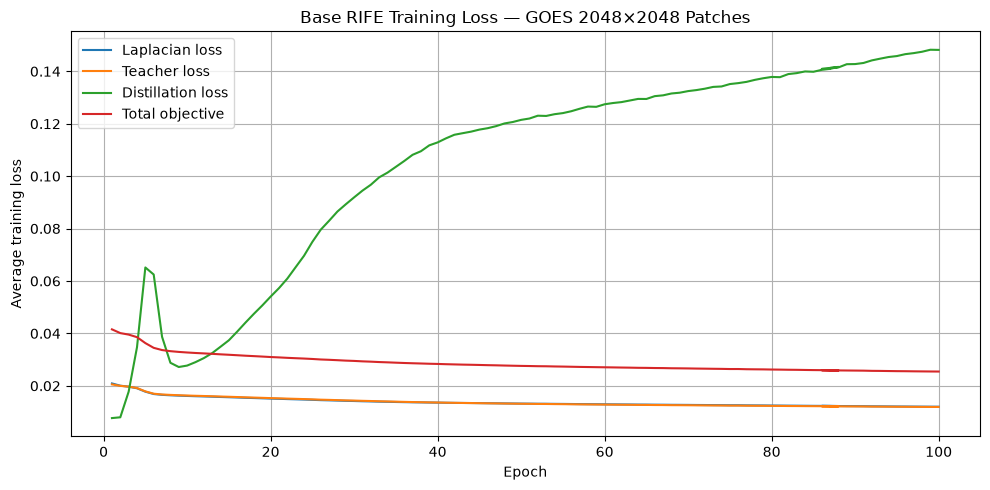

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)
CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)
EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
history = pd.read_csv(EPOCH_LOG)

plt.figure(figsize=(10, 5))
plt.plot(history["epoch"], history["avg_loss_l1"], label="Laplacian loss")
plt.plot(history["epoch"], history["avg_loss_teacher"], label="Teacher loss")
plt.plot(history["epoch"], history["avg_loss_distill"], label="Distillation loss")
plt.plot(history["epoch"], history["avg_total_loss"], label="Total objective")

plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Base RIFE Training Loss — GOES 2048×2048 Patches")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Graph saved successfully at:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/RIFE_base_2048_training_loss.png


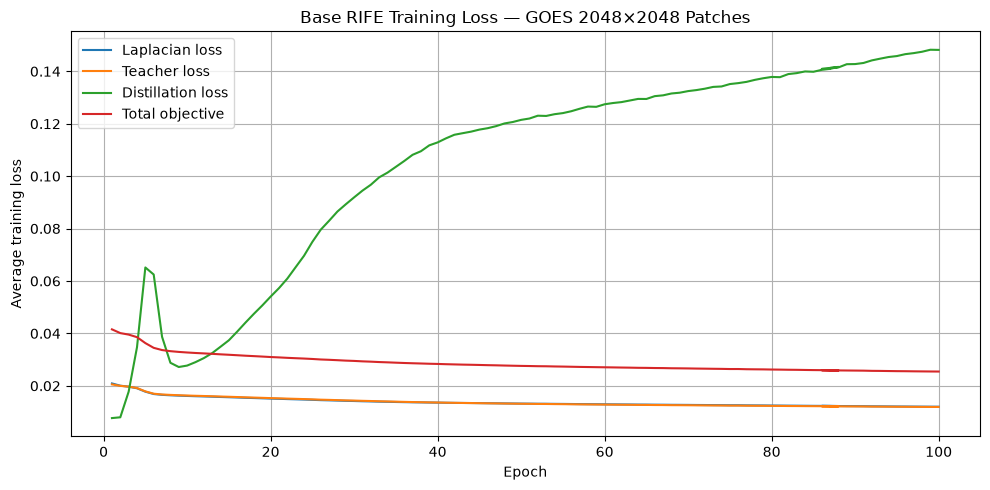

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
history = pd.read_csv(EPOCH_LOG)

plt.figure(figsize=(10, 5))

plt.plot(history["epoch"], history["avg_loss_l1"], label="Laplacian loss")
plt.plot(history["epoch"], history["avg_loss_teacher"], label="Teacher loss")
plt.plot(history["epoch"], history["avg_loss_distill"], label="Distillation loss")
plt.plot(history["epoch"], history["avg_total_loss"], label="Total objective")

plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Base RIFE Training Loss — GOES 2048×2048 Patches")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the graph
OUTPUT_PATH = CHECKPOINT_DIR / "RIFE_base_2048_training_loss.png"

plt.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight")

print(f"Graph saved successfully at:\n{OUTPUT_PATH}")

plt.show()

In [3]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

DATA_DIR = PROJECT_DIR / "Dataset" / "GOES_Preprocessed_200_320"
TEST_CSV = DATA_DIR / "test_triplets_preprocessed.csv"

assert TEST_CSV.exists(), f"Test CSV not found: {TEST_CSV}"

test_df = pd.read_csv(TEST_CSV)

print("Test triplets:", len(test_df))
print("Columns:", test_df.columns.tolist())
display(test_df.head(3))

Test triplets: 253
Columns: ['input_0', 'target', 'input_2', 'mask_0', 'mask_target', 'mask_2', 'time_0', 'time_1', 'time_2']


,input_0,target,input_2,mask_0,mask_target,mask_2,time_0,time_1,time_2
0,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 01:50:20,2026-07-14 02:00:20,2026-07-14 02:10:20
1,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:00:20,2026-07-14 02:10:20,2026-07-14 02:20:20
2,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2026-07-14 02:10:20,2026-07-14 02:20:20,2026-07-14 02:30:20


In [4]:
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PATCH_SIZE = 2048
STRIDE = 2048
MIN_VALID_RATIO = 0.95

TEST_PATCH_DIR = PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"

# Safety check: don't overwrite an existing test-patch collection.
if TEST_PATCH_DIR.exists() and any(TEST_PATCH_DIR.iterdir()):
    raise RuntimeError(
        f"{TEST_PATCH_DIR} is not empty. "
        "Inspect the existing files before rerunning extraction."
    )

for folder in ["img0", "gt", "img2", "mask0", "mask_gt", "mask2"]:
    (TEST_PATCH_DIR / folder).mkdir(parents=True, exist_ok=True)

records = []
patch_counter = 0
rejected_validity = 0
rejected_nonfinite = 0
rejected_size = 0

required = [
    "input_0", "target", "input_2",
    "mask_0", "mask_target", "mask_2"
]
missing = [c for c in required if c not in test_df.columns]
assert not missing, f"Missing test CSV columns: {missing}"

def load_array(path):
    return np.load(path)

for triplet_idx, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Extracting test patches"
):
    img0 = load_array(row["input_0"])
    gt = load_array(row["target"])
    img2 = load_array(row["input_2"])

    mask0 = load_array(row["mask_0"])
    mask_gt = load_array(row["mask_target"])
    mask2 = load_array(row["mask_2"])

    arrays = [img0, gt, img2, mask0, mask_gt, mask2]

    if any(a.ndim != 2 for a in arrays):
        raise ValueError(
            f"Expected 2D arrays at test triplet row {triplet_idx}: "
            f"{[a.shape for a in arrays]}"
        )

    h, w = img0.shape
    if any(a.shape != (h, w) for a in arrays):
        raise ValueError(
            f"Shape mismatch at test triplet row {triplet_idx}: "
            f"{[a.shape for a in arrays]}"
        )

    if h < PATCH_SIZE or w < PATCH_SIZE:
        rejected_size += 1
        continue

    # Same edge-adjusted patch positions as training extraction
    ys = sorted(set(
        list(range(0, h - PATCH_SIZE + 1, STRIDE))
        + [h - PATCH_SIZE]
    ))
    xs = sorted(set(
        list(range(0, w - PATCH_SIZE + 1, STRIDE))
        + [w - PATCH_SIZE]
    ))

    for y in ys:
        for x in xs:
            sl = np.s_[y:y + PATCH_SIZE, x:x + PATCH_SIZE]

            m0 = np.asarray(mask0[sl]) > 0
            mg = np.asarray(mask_gt[sl]) > 0
            m2 = np.asarray(mask2[sl]) > 0

            ratios = [
                float(m0.mean()),
                float(mg.mean()),
                float(m2.mean())
            ]

            if min(ratios) < MIN_VALID_RATIO:
                rejected_validity += 1
                continue

            p0 = np.asarray(img0[sl], dtype=np.float32)
            pg = np.asarray(gt[sl], dtype=np.float32)
            p2 = np.asarray(img2[sl], dtype=np.float32)

            if not all(np.isfinite(a).all() for a in [p0, pg, p2]):
                rejected_nonfinite += 1
                continue

            patch_id = f"test_patch_{patch_counter:07d}"

            paths = {
                "img0_path": TEST_PATCH_DIR / "img0" / f"{patch_id}.npy",
                "gt_path": TEST_PATCH_DIR / "gt" / f"{patch_id}.npy",
                "img2_path": TEST_PATCH_DIR / "img2" / f"{patch_id}.npy",
                "mask0_path": TEST_PATCH_DIR / "mask0" / f"{patch_id}.npy",
                "mask_gt_path": TEST_PATCH_DIR / "mask_gt" / f"{patch_id}.npy",
                "mask2_path": TEST_PATCH_DIR / "mask2" / f"{patch_id}.npy",
            }

            np.save(paths["img0_path"], p0.astype(np.float16))
            np.save(paths["gt_path"], pg.astype(np.float16))
            np.save(paths["img2_path"], p2.astype(np.float16))

            np.save(paths["mask0_path"], m0.astype(np.uint8))
            np.save(paths["mask_gt_path"], mg.astype(np.uint8))
            np.save(paths["mask2_path"], m2.astype(np.uint8))

            records.append({
                "patch_id": patch_id,
                **{k: str(v) for k, v in paths.items()},
                "source_triplet_index": int(triplet_idx),
                "y": int(y),
                "x": int(x),
                "valid_ratio_img0": ratios[0],
                "valid_ratio_gt": ratios[1],
                "valid_ratio_img2": ratios[2],
            })

            patch_counter += 1

test_patch_df = pd.DataFrame(records)
TEST_MANIFEST = TEST_PATCH_DIR / "test_patches.csv"
test_patch_df.to_csv(TEST_MANIFEST, index=False)

print("\nTEST PATCH EXTRACTION COMPLETE")
print("Test triplets processed:", len(test_df))
print("Test patches saved:", len(test_patch_df))
print("Rejected for validity threshold:", rejected_validity)
print("Rejected for non-finite image values:", rejected_nonfinite)
print("Triplets too small:", rejected_size)
print("Manifest:", TEST_MANIFEST)

assert len(test_patch_df) > 0, "No test patches were extracted."

Extracting test patches:   0%|          | 0/253 [00:00<?, ?it/s]


TEST PATCH EXTRACTION COMPLETE
Test triplets processed: 253
Test patches saved: 1265
Rejected for validity threshold: 1012
Rejected for non-finite image values: 0
Triplets too small: 0
Manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv


In [5]:
import numpy as np
import pandas as pd
from pathlib import Path

test_patch_df = pd.read_csv(TEST_MANIFEST)

file_cols = [
    "img0_path", "gt_path", "img2_path",
    "mask0_path", "mask_gt_path", "mask2_path"
]

missing_files = []
bad_shapes = []

for _, row in test_patch_df.iterrows():
    for col in file_cols:
        path = Path(row[col])

        if not path.is_file():
            missing_files.append(str(path))
            continue

        arr = np.load(path, mmap_mode="r")

        if arr.shape != (2048, 2048):
            bad_shapes.append((str(path), arr.shape))

print("Test patches:", len(test_patch_df))
print("Missing files:", len(missing_files))
print("Incorrect shapes:", len(bad_shapes))

assert not missing_files, missing_files[:5]
assert not bad_shapes, bad_shapes[:5]

print("Test patch verification passed.")

Test patches: 1265
Missing files: 0
Incorrect shapes: 0
Test patch verification passed.


In [2]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_PATCH_DIR = PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"
TEST_MANIFEST = TEST_PATCH_DIR / "test_patches.csv"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_base_2048"
)

# 1. Verify test patches
print("Test patch directory exists:", TEST_PATCH_DIR.exists())
print("Test manifest exists:", TEST_MANIFEST.exists())

if TEST_MANIFEST.exists():
    test_df = pd.read_csv(TEST_MANIFEST)
    print("Total test patches:", len(test_df))
    print("Columns:", test_df.columns.tolist())
    display(test_df.head())
else:
    print("Test patches are not ready.")
    print("Run the test-patch extraction cell first.")

# 2. Locate model checkpoints
print("\nCheckpoint directory exists:", CHECKPOINT_DIR.exists())

if CHECKPOINT_DIR.exists():
    checkpoints = sorted(CHECKPOINT_DIR.glob("*.pth"))

    if checkpoints:
        for path in checkpoints:
            print(
                f"{path.name} | "
                f"{path.stat().st_size / (1024**3):.3f} GB"
            )
    else:
        print("No .pth checkpoints found in this directory.")
else:
    print("Checkpoint directory not found.")

# 3. Search project directory for epoch 76
print("\nSearching for epoch_100.pth ...")
matches = list(PROJECT_DIR.rglob("epoch_076.pth"))

if matches:
    for path in matches:
        print("Found:", path)
else:
    print("epoch_100.pth was not found.")
    print("Use the checkpoint filename printed above.")


Test patch directory exists: True
Test manifest exists: True
Total test patches: 1265
Columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']


,patch_id,img0_path,gt_path,img2_path,mask0_path,mask_gt_path,mask2_path,source_triplet_index,y,x,valid_ratio_img0,valid_ratio_gt,valid_ratio_img2
0,test_patch_0000000,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,0,2048,0.951001,0.951001,0.951001
1,test_patch_0000001,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,0,0.954970,0.954970,0.954970
2,test_patch_0000002,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,2048,1.000000,1.000000,1.000000
3,test_patch_0000003,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,2048,3376,0.954970,0.954970,0.954970
4,test_patch_0000004,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,0,3376,2048,0.951055,0.951040,0.951040



Checkpoint directory exists: True
epoch_001.pth | 0.120 GB
epoch_002.pth | 0.120 GB
epoch_003.pth | 0.120 GB
epoch_004.pth | 0.120 GB
epoch_005.pth | 0.120 GB
epoch_006.pth | 0.120 GB
epoch_007.pth | 0.120 GB
epoch_008.pth | 0.120 GB
epoch_009.pth | 0.120 GB
epoch_010.pth | 0.120 GB
epoch_011.pth | 0.120 GB
epoch_012.pth | 0.120 GB
epoch_013.pth | 0.120 GB
epoch_014.pth | 0.120 GB
epoch_015.pth | 0.120 GB
epoch_016.pth | 0.120 GB
epoch_017.pth | 0.120 GB
epoch_018.pth | 0.120 GB
epoch_019.pth | 0.120 GB
epoch_020.pth | 0.120 GB
epoch_021.pth | 0.120 GB
epoch_022.pth | 0.120 GB
epoch_023.pth | 0.120 GB
epoch_024.pth | 0.120 GB
epoch_025.pth | 0.120 GB
epoch_026.pth | 0.120 GB
epoch_027.pth | 0.120 GB
epoch_028.pth | 0.120 GB
epoch_029.pth | 0.120 GB
epoch_030.pth | 0.120 GB
epoch_031.pth | 0.120 GB
epoch_032.pth | 0.120 GB
epoch_033.pth | 0.120 GB
epoch_034.pth | 0.120 GB
epoch_035.pth | 0.120 GB
epoch_036.pth | 0.120 GB
epoch_037.pth | 0.120 GB
epoch_038.pth | 0.120 GB
epoch_039.pth |

In [3]:

import sys
import torch
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OFFICIAL_RIFE = PROJECT_DIR / "Official_RIFE"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_base_2048"
    / "epoch_100.pth"
)

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

assert OFFICIAL_RIFE.exists(), (
    f"Official RIFE directory not found: {OFFICIAL_RIFE}"
)

# Import the same RIFE implementation used during training
sys.path.insert(0, str(OFFICIAL_RIFE))

from model.RIFE import Model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Initialize model
rife_model = Model()

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "flownet_state_dict" in checkpoint:
        state_dict = checkpoint["flownet_state_dict"]
    else:
        # Handle a checkpoint that directly contains model weights
        state_dict = checkpoint
else:
    raise TypeError("Unexpected checkpoint format.")

# Load trained network weights
result = rife_model.flownet.load_state_dict(
    state_dict,
    strict=True
)

rife_model.flownet.to(device)
rife_model.eval()

print("\nCheckpoint loaded successfully.")
print("Checkpoint:", CHECKPOINT_PATH.name)

if isinstance(checkpoint, dict):
    print("Completed epochs:", checkpoint.get("completed_epochs", "Not recorded"))

print("Model ready for test inference.")


Device: cuda
GPU: NVIDIA H200 NVL

Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'learning_rate', 'patch_size', 'training_patches', 'epoch_stats']

Checkpoint loaded successfully.
Checkpoint: epoch_100.pth
Completed epochs: 100
Model ready for test inference.


In [5]:

import sys
import inspect
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

# -------------------------------------------------------
# 1. Paths and settings
# -------------------------------------------------------
PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_MANIFEST = (
    PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results" / "RIFE_base_epoch100_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PATCH_RESULTS = OUTPUT_DIR / "per_patch_metrics.csv"
SUMMARY_RESULTS = OUTPUT_DIR / "summary_metrics.csv"

BT_MIN_K = 200.0
BT_MAX_K = 320.0
BT_RANGE_K = BT_MAX_K - BT_MIN_K
DATA_RANGE = 1.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert TEST_MANIFEST.exists(), f"Missing: {TEST_MANIFEST}"

test_df = pd.read_csv(TEST_MANIFEST)
print("Test patches:", len(test_df))
print("Device:", device)

# FSIM implementation
try:
    import piq
except ImportError as exc:
    raise ImportError(
        "FSIM requires piq. Run `%pip install piq` in another cell, "
        "then rerun this evaluation cell."
    ) from exc

# -------------------------------------------------------
# 2. Check the loaded model
# -------------------------------------------------------
rife_model.flownet.to(device)
rife_model.eval()

inference_signature = inspect.signature(rife_model.inference)
print("RIFE inference signature:", inference_signature)

# Support common Official RIFE wrapper signatures.
inference_parameters = list(inference_signature.parameters.keys())
print("Inference parameters:", inference_parameters)

# -------------------------------------------------------
# 3. Helpers
# -------------------------------------------------------
def load_array(path):
    arr = np.load(path, allow_pickle=False)
    return np.asarray(arr).squeeze()

def to_rgb_tensor(arr):
    # GOES single-channel input -> 3 channels for RIFE
    arr = np.asarray(arr, dtype=np.float32)
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    arr = np.clip(arr, 0.0, 1.0)
    tensor = torch.from_numpy(arr).unsqueeze(0).unsqueeze(0)
    return tensor.repeat(1, 3, 1, 1).to(device)

@torch.inference_mode()
def predict_middle(img0, img2):
    # Determine whether this wrapper accepts two images or a
    # concatenated six-channel tensor.
    params = list(inspect.signature(rife_model.inference).parameters.keys())

    if len(params) >= 2 and params[0] in (
        "img0", "img1", "image0", "image1"
    ):
        pred = rife_model.inference(img0, img2)
    else:
        imgs = torch.cat([img0, img2], dim=1)
        pred = rife_model.inference(imgs)

    if isinstance(pred, (tuple, list)):
        pred = pred[0]

    if isinstance(pred, dict):
        raise TypeError(
            "Inference returned a dictionary. Inspect the return value "
            "and select its predicted middle-frame tensor."
        )

    if pred.ndim == 3:
        pred = pred.unsqueeze(0)

    # RIFE output is expected to be [1,3,H,W].
    if pred.ndim != 4:
        raise ValueError(f"Unexpected prediction shape: {pred.shape}")

    pred = pred[:, :1, :, :]  # repeated channels; keep one BT channel
    return pred[0, 0].float().clamp(0, 1).cpu().numpy()

def compute_fsim(pred, gt):
    # FSIM is evaluated on the full patch. The pixelwise error and
    # brightness-temperature metrics below use the valid GT mask.
    p = torch.from_numpy(pred).float()[None, None].to(device)
    g = torch.from_numpy(gt).float()[None, None].to(device)

    # PIQ FSIM supports image tensors; repeat grayscale into RGB.
    p = p.repeat(1, 3, 1, 1)
    g = g.repeat(1, 3, 1, 1)

    with torch.inference_mode():
        score = piq.fsim(p, g, data_range=1.0, reduction="mean")

    return float(score.detach().cpu())

# -------------------------------------------------------
# 4. Evaluate every test patch
# -------------------------------------------------------
patch_rows = []

total_squared_error = 0.0
total_absolute_error = 0.0
total_signed_error = 0.0
total_squared_bt_error = 0.0
total_absolute_bt_error = 0.0
total_signed_bt_error = 0.0
total_valid_pixels = 0

for row in tqdm(
    test_df.itertuples(index=False),
    total=len(test_df),
    desc="Evaluating RIFE"
):
    img0 = load_array(row.img0_path).astype(np.float32)
    gt = load_array(row.gt_path).astype(np.float32)
    img2 = load_array(row.img2_path).astype(np.float32)
    mask_gt = load_array(row.mask_gt_path)

    if not (img0.shape == gt.shape == img2.shape == mask_gt.shape):
        raise ValueError(
            f"Shape mismatch in {row.patch_id}: "
            f"{img0.shape}, {gt.shape}, {img2.shape}, {mask_gt.shape}"
        )

    # Valid pixels: ground-truth mask and finite normalized values.
    valid = (
        (mask_gt > 0)
        & np.isfinite(gt)
        & np.isfinite(img0)
        & np.isfinite(img2)
    )

    if not np.any(valid):
        print("Skipping patch with no valid pixels:", row.patch_id)
        continue

    img0 = np.nan_to_num(img0, nan=0.0, posinf=0.0, neginf=0.0)
    img2 = np.nan_to_num(img2, nan=0.0, posinf=0.0, neginf=0.0)
    gt = np.nan_to_num(gt, nan=0.0, posinf=0.0, neginf=0.0)

    img0_tensor = to_rgb_tensor(img0)
    img2_tensor = to_rgb_tensor(img2)

    pred = predict_middle(img0_tensor, img2_tensor)

    if pred.shape != gt.shape:
        raise ValueError(
            f"Prediction shape {pred.shape} != GT shape {gt.shape} "
            f"for {row.patch_id}"
        )

    # Normalized image errors only on valid GT pixels
    err = pred[valid] - gt[valid]
    patch_mse = float(np.mean(err ** 2))
    patch_mae = float(np.mean(np.abs(err)))
    patch_rmse = float(np.sqrt(patch_mse))
    patch_psnr = (
        float("inf") if patch_mse == 0
        else float(10.0 * np.log10(DATA_RANGE ** 2 / patch_mse))
    )

    # Structural metrics are computed on the complete patch.
    # Invalid areas are zero-filled in the preprocessed dataset.
    patch_ssim = float(
        structural_similarity(
            np.clip(gt, 0, 1),
            np.clip(pred, 0, 1),
            data_range=DATA_RANGE,
            gaussian_weights=True,
            sigma=1.5,
            use_sample_covariance=False
        )
    )

    patch_fsim = compute_fsim(
        np.clip(pred, 0, 1),
        np.clip(gt, 0, 1)
    )

    # Convert normalized brightness temperatures back to Kelvin.
    pred_bt = BT_MIN_K + np.clip(pred, 0, 1) * BT_RANGE_K
    gt_bt = BT_MIN_K + np.clip(gt, 0, 1) * BT_RANGE_K

    bt_err = pred_bt[valid] - gt_bt[valid]

    bt_mae = float(np.mean(np.abs(bt_err)))
    bt_rmse = float(np.sqrt(np.mean(bt_err ** 2)))
    bt_bias = float(np.mean(bt_err))  # prediction minus ground truth

    n_valid = int(valid.sum())

    # Accumulate pixel-weighted global metrics
    total_squared_error += float(np.sum(err ** 2))
    total_absolute_error += float(np.sum(np.abs(err)))
    total_signed_error += float(np.sum(err))
    total_squared_bt_error += float(np.sum(bt_err ** 2))
    total_absolute_bt_error += float(np.sum(np.abs(bt_err)))
    total_signed_bt_error += float(np.sum(bt_err))
    total_valid_pixels += n_valid

    patch_rows.append({
        "patch_id": row.patch_id,
        "valid_pixels": n_valid,
        "MSE": patch_mse,
        "PSNR_dB": patch_psnr,
        "SSIM": patch_ssim,
        "FSIM": patch_fsim,
        "BT_MAE_K": bt_mae,
        "BT_RMSE_K": bt_rmse,
        "BT_Bias_K": bt_bias
    })

    # Save progress periodically so results survive a kernel restart.
    if len(patch_rows) % 10 == 0:
        pd.DataFrame(patch_rows).to_csv(PATCH_RESULTS, index=False)

# Save all per-patch results
patch_results_df = pd.DataFrame(patch_rows)
patch_results_df.to_csv(PATCH_RESULTS, index=False)

if total_valid_pixels == 0:
    raise RuntimeError("No valid test pixels were evaluated.")

# -------------------------------------------------------
# 5. Calculate global pixel-weighted summary metrics
# -------------------------------------------------------
global_mse = total_squared_error / total_valid_pixels
global_mae = total_absolute_error / total_valid_pixels
global_rmse = np.sqrt(global_mse)
global_psnr = (
    float("inf") if global_mse == 0
    else 10.0 * np.log10(DATA_RANGE ** 2 / global_mse)
)

summary = {
    "Model": "Base RIFE",
    "Checkpoint": "epoch_100.pth",
    "Evaluated_patches": len(patch_results_df),
    "Valid_pixels": total_valid_pixels,
    "MSE": global_mse,
    "PSNR_dB": global_psnr,
    "SSIM_mean_patch": patch_results_df["SSIM"].mean(),
    "FSIM_mean_patch": patch_results_df["FSIM"].mean(),
    "BT_MAE_K": total_absolute_bt_error / total_valid_pixels,
    "BT_RMSE_K": np.sqrt(
        total_squared_bt_error / total_valid_pixels
    ),
    "BT_Bias_K": total_signed_bt_error / total_valid_pixels
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv(SUMMARY_RESULTS, index=False)

print("\n========== RIFE TEST RESULTS ==========")
display(summary_df)

print("\nPer-patch results saved to:")
print(PATCH_RESULTS)

print("\nSummary saved to:")
print(SUMMARY_RESULTS)


Test patches: 1265
Device: cuda
RIFE inference signature: (img0, img1, scale=1, scale_list=None, TTA=False, timestep=0.5)
Inference parameters: ['img0', 'img1', 'scale', 'scale_list', 'TTA', 'timestep']


Evaluating RIFE:   0%|          | 0/1265 [00:00<?, ?it/s]


========== RIFE TEST RESULTS ==========


,Model,Checkpoint,Evaluated_patches,Valid_pixels,MSE,PSNR_dB,SSIM_mean_patch,FSIM_mean_patch,BT_MAE_K,BT_RMSE_K,BT_Bias_K
0,Base RIFE,epoch_100.pth,1265,5106310063,0.000242,36.153835,0.942558,0.997844,0.886762,1.868484,-0.060149



Per-patch results saved to:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/RIFE_base_epoch100_test/per_patch_metrics.csv

Summary saved to:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/RIFE_base_epoch100_test/summary_metrics.csv


Device: cuda
GPU: NVIDIA H200 NVL

Selected patch: test_patch_0000000
Source triplet index: 0
Input 1 timestamp: 2026-07-14 01:50:20
GT timestamp: 2026-07-14 02:00:20
Input 2 timestamp: 2026-07-14 02:10:20
Input I0 shape: (2048, 2048)
Ground truth shape: (2048, 2048)
Input I2 shape: (2048, 2048)
GT mask shape: (2048, 2048)

Loaded checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_base_2048/epoch_100.pth
Completed epochs: 100

========== RIFE PATCH METRICS ==========
Patch: test_patch_0000000
Valid pixels: 3988789
MSE (normalized): 0.00036284
MAE (normalized): 0.00948043
RMSE (normalized): 0.01904841
PSNR: 34.4028 dB
BT-MAE: 1.1377 K
BT-RMSE: 2.2858 K
BT-Bias: -0.0561 K


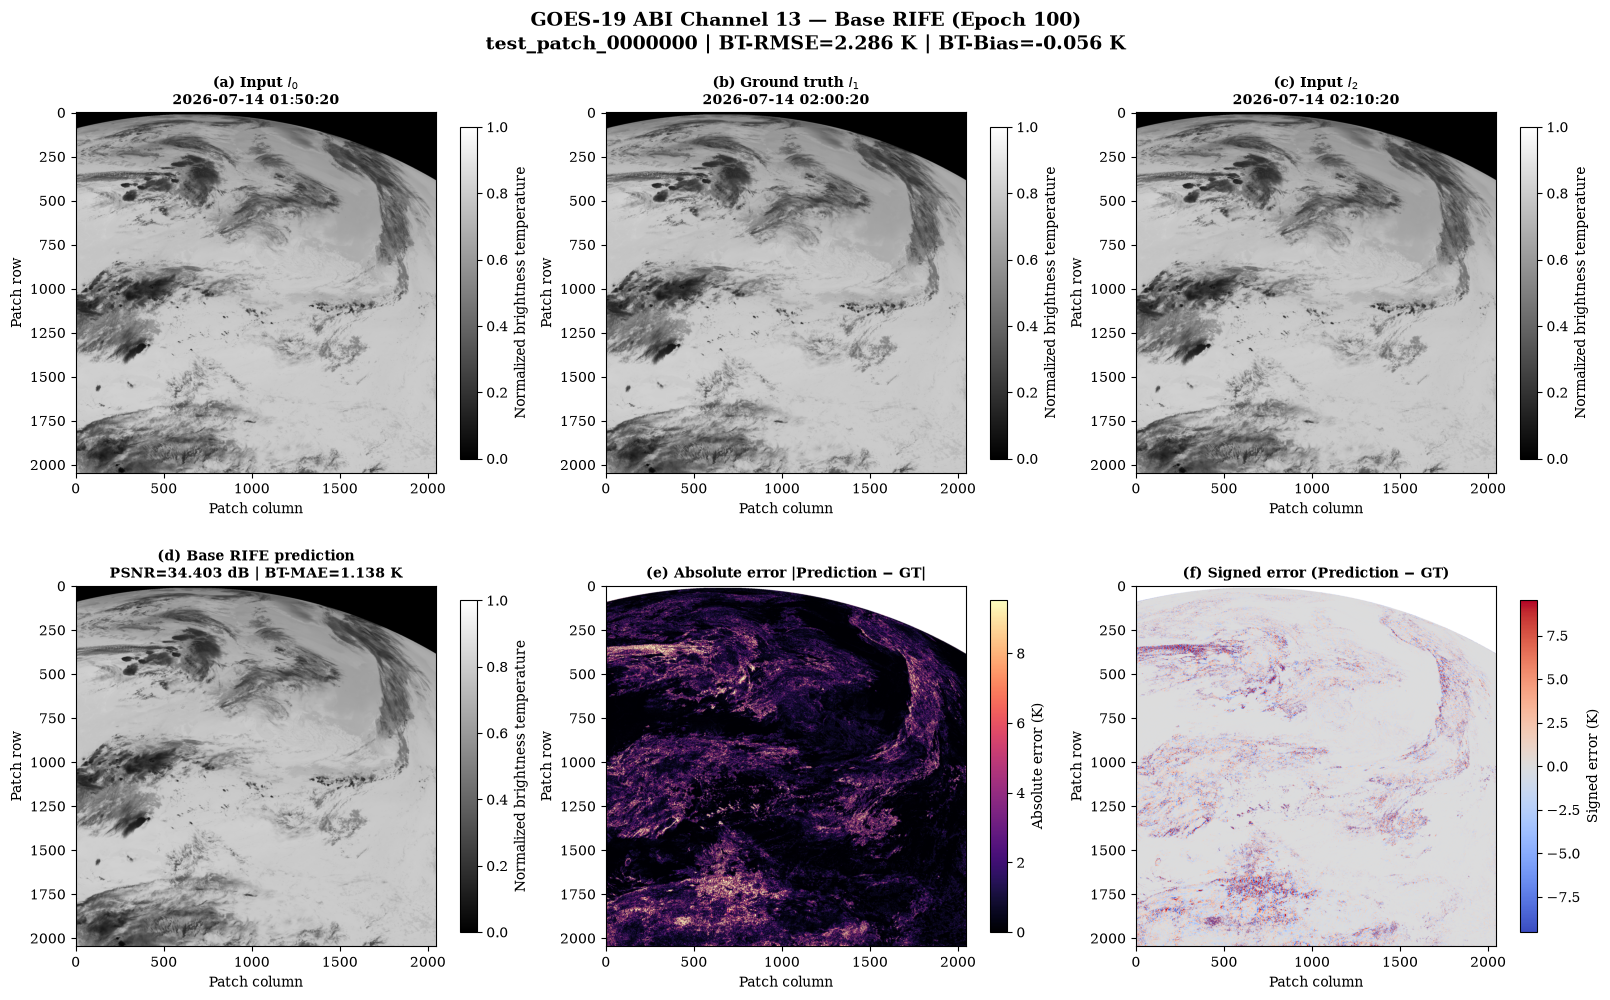


Saved outputs:
PNG: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/paper_figures_RIFE_epoch100/test_patch_0000000_RIFE_epoch100_error_maps.png
PDF: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/paper_figures_RIFE_epoch100/test_patch_0000000_RIFE_epoch100_error_maps.pdf
Arrays: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/paper_figures_RIFE_epoch100


In [1]:
# ================================================================
# PAPER FIGURE: GOES-19 2048x2048 PATCH — BASE RIFE EPOCH 100
#
# (a) Input I0 with timestamp
# (b) Ground truth I1 with timestamp
# (c) Input I2 with timestamp
# (d) RIFE prediction at the middle timestamp
# (e) Absolute error in brightness temperature (K)
# (f) Signed error in brightness temperature (K)
#
# Uses:
#   - GOES_TestPatches_2048/test_patches.csv
#   - GOES_TestNEW/test_triplets.csv for timestamps
#   - RIFE_base_2048/epoch_100.pth
#   - 200–320 K normalization range
# ================================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------

PROJECT = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RIFE_DIR = PROJECT / "Official_RIFE"

PATCH_MANIFEST = (
    PROJECT / "Dataset" / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

TRIPLET_CSV = (
    PROJECT / "Dataset" / "GOES_TestNEW"
    / "test_triplets.csv"
)

CHECKPOINT = (
    PROJECT / "checkpoints_NEW" / "RIFE_base_2048"
    / "epoch_100.pth"
)

OUT_DIR = PROJECT / "results" / "paper_figures_RIFE_epoch100"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BT_MIN_K = 200.0
BT_MAX_K = 320.0
BT_RANGE_K = BT_MAX_K - BT_MIN_K

# Select the row number in the test-patch manifest.
# 0 = first patch, 1 = second patch, etc.
PATCH_INDEX = 0

# Shared error-map display range, based on the 99th percentile.
ERROR_PERCENTILE = 99

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

for path in [RIFE_DIR, PATCH_MANIFEST, TRIPLET_CSV, CHECKPOINT]:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------
# 2. LOAD PATCH MANIFEST AND SELECT ONE PATCH
# ------------------------------------------------

patch_df = pd.read_csv(PATCH_MANIFEST)
triplet_df = pd.read_csv(TRIPLET_CSV)

if not 0 <= PATCH_INDEX < len(patch_df):
    raise IndexError(
        f"PATCH_INDEX must be between 0 and {len(patch_df)-1}"
    )

patch_row = patch_df.iloc[PATCH_INDEX]

required_patch_cols = [
    "patch_id",
    "source_triplet_index",
    "img0_path",
    "gt_path",
    "img2_path",
    "mask_gt_path",
]

missing = [c for c in required_patch_cols if c not in patch_df.columns]
if missing:
    raise ValueError(f"Missing test-patch columns: {missing}")

triplet_index = int(patch_row["source_triplet_index"])

if not 0 <= triplet_index < len(triplet_df):
    raise IndexError(
        f"Invalid source_triplet_index={triplet_index} "
        f"for {len(triplet_df)} test triplets."
    )

time_row = triplet_df.iloc[triplet_index]

for col in ["time_0", "time_1", "time_2"]:
    if col not in triplet_df.columns:
        raise ValueError(
            f"Timestamp column '{col}' is missing from {TRIPLET_CSV}"
        )

print("\nSelected patch:", patch_row["patch_id"])
print("Source triplet index:", triplet_index)
print("Input 1 timestamp:", time_row["time_0"])
print("GT timestamp:", time_row["time_1"])
print("Input 2 timestamp:", time_row["time_2"])

# ------------------------------------------------
# 3. LOAD INPUTS, GT AND VALIDITY MASK
# ------------------------------------------------

def load_npy(path):
    path = Path(str(path))
    if not path.exists():
        raise FileNotFoundError(path)

    return np.load(path, allow_pickle=False).squeeze().astype(np.float32)


img0 = load_npy(patch_row["img0_path"])
gt = load_npy(patch_row["gt_path"])
img2 = load_npy(patch_row["img2_path"])
mask_gt = load_npy(patch_row["mask_gt_path"]) > 0

expected_shape = (2048, 2048)

for name, arr in [
    ("Input I0", img0),
    ("Ground truth", gt),
    ("Input I2", img2),
    ("GT mask", mask_gt),
]:
    print(name, "shape:", arr.shape)

    if arr.shape != expected_shape:
        raise ValueError(
            f"{name} should have shape {expected_shape}, got {arr.shape}"
        )

# ------------------------------------------------
# 4. LOAD THE EPOCH-100 RIFE CHECKPOINT
# ------------------------------------------------

if str(RIFE_DIR) not in sys.path:
    sys.path.insert(0, str(RIFE_DIR))

from model.RIFE import Model

rife_model = Model()

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "flownet_state_dict" in checkpoint:
    state_dict = checkpoint["flownet_state_dict"]
else:
    raise KeyError(
        "Could not find model_state_dict, state_dict, or "
        "flownet_state_dict in checkpoint. Inspect checkpoint keys."
    )

rife_model.flownet.load_state_dict(state_dict, strict=True)
rife_model.flownet.to(DEVICE)
rife_model.eval()

print("\nLoaded checkpoint:", CHECKPOINT)
if isinstance(checkpoint, dict):
    print("Completed epochs:", checkpoint.get("completed_epochs", "unknown"))

# ------------------------------------------------
# 5. PREDICT THE MIDDLE FRAME WITH RIFE
# ------------------------------------------------

def to_rgb_tensor(image):
    # Data was preprocessed to normalized [0,1] brightness values.
    image = np.nan_to_num(
        image, nan=0.0, posinf=0.0, neginf=0.0
    )
    image = np.clip(image, 0.0, 1.0)

    tensor = torch.from_numpy(
        image.astype(np.float32)
    )[None, None, :, :]

    # GOES imagery is grayscale, while RIFE expects 3 channels.
    return tensor.repeat(1, 3, 1, 1).to(DEVICE)


with torch.inference_mode():
    prediction_tensor = rife_model.inference(
        to_rgb_tensor(img0),
        to_rgb_tensor(img2),
        timestep=0.5
    )

if isinstance(prediction_tensor, (tuple, list)):
    tensors = [
        value for value in prediction_tensor
        if torch.is_tensor(value)
    ]
    if not tensors:
        raise TypeError("RIFE returned no prediction tensor.")
    prediction_tensor = tensors[0]

prediction = (
    prediction_tensor[0, 0]
    .detach()
    .float()
    .cpu()
    .numpy()
    .astype(np.float32)
)

if prediction.shape != gt.shape:
    raise ValueError(
        f"Prediction shape {prediction.shape} differs from GT {gt.shape}"
    )

prediction = np.clip(prediction, 0.0, 1.0)

# ------------------------------------------------
# 6. COMPUTE ERROR MAPS IN KELVIN
# ------------------------------------------------

# Normalization used in this notebook:
# normalized = (brightness_temperature - 200) / 120
#
# Difference in Kelvin = normalized difference * 120.
valid = (
    mask_gt
    & np.isfinite(gt)
    & np.isfinite(prediction)
)

if not np.any(valid):
    raise ValueError("No valid ground-truth pixels in this patch.")

signed_error_k = np.full(gt.shape, np.nan, dtype=np.float32)
absolute_error_k = np.full(gt.shape, np.nan, dtype=np.float32)

signed_error_k[valid] = (
    prediction[valid] - gt[valid]
) * BT_RANGE_K

absolute_error_k[valid] = np.abs(signed_error_k[valid])

# Pixel-weighted metrics on valid pixels only.
normalized_error = prediction[valid] - gt[valid]

mse = float(np.mean(normalized_error ** 2))
mae = float(np.mean(np.abs(normalized_error)))
rmse = float(np.sqrt(mse))
psnr = float("inf") if mse == 0 else float(10 * np.log10(1.0 / mse))

bt_mae = float(np.mean(absolute_error_k[valid]))
bt_rmse = float(np.sqrt(np.mean(signed_error_k[valid] ** 2)))
bt_bias = float(np.mean(signed_error_k[valid]))

abs_limit = max(
    float(np.nanpercentile(absolute_error_k[valid], ERROR_PERCENTILE)),
    0.1
)

signed_limit = max(
    float(np.nanpercentile(np.abs(signed_error_k[valid]), ERROR_PERCENTILE)),
    0.1
)

print("\n========== RIFE PATCH METRICS ==========")
print("Patch:", patch_row["patch_id"])
print("Valid pixels:", int(valid.sum()))
print(f"MSE (normalized): {mse:.8f}")
print(f"MAE (normalized): {mae:.8f}")
print(f"RMSE (normalized): {rmse:.8f}")
print(f"PSNR: {psnr:.4f} dB")
print(f"BT-MAE: {bt_mae:.4f} K")
print(f"BT-RMSE: {bt_rmse:.4f} K")
print(f"BT-Bias: {bt_bias:.4f} K")

# ------------------------------------------------
# 7. PUBLICATION-STYLE SIX-PANEL FIGURE
# ------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 10,
    "figure.titlesize": 14,
})

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

# (a) Input 1
im = axes[0, 0].imshow(
    img0, cmap="gray", vmin=0, vmax=1
)
axes[0, 0].set_title(
    f"(a) Input $I_0$\n{time_row['time_0']}",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[0, 0], fraction=0.046, pad=0.04,
             label="Normalized brightness temperature")

# (b) Ground truth
im = axes[0, 1].imshow(
    gt, cmap="gray", vmin=0, vmax=1
)
axes[0, 1].set_title(
    f"(b) Ground truth $I_1$\n{time_row['time_1']}",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[0, 1], fraction=0.046, pad=0.04,
             label="Normalized brightness temperature")

# (c) Input 2
im = axes[0, 2].imshow(
    img2, cmap="gray", vmin=0, vmax=1
)
axes[0, 2].set_title(
    f"(c) Input $I_2$\n{time_row['time_2']}",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.04,
             label="Normalized brightness temperature")

# (d) RIFE prediction
im = axes[1, 0].imshow(
    prediction, cmap="gray", vmin=0, vmax=1
)
axes[1, 0].set_title(
    f"(d) Base RIFE prediction\n"
    f"PSNR={psnr:.3f} dB | BT-MAE={bt_mae:.3f} K",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04,
             label="Normalized brightness temperature")

# (e) Absolute error map
im = axes[1, 1].imshow(
    absolute_error_k,
    cmap="magma",
    vmin=0,
    vmax=abs_limit
)
axes[1, 1].set_title(
    "(e) Absolute error |Prediction − GT|",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04,
             label="Absolute error (K)")

# (f) Signed error map
im = axes[1, 2].imshow(
    signed_error_k,
    cmap="coolwarm",
    vmin=-signed_limit,
    vmax=signed_limit
)
axes[1, 2].set_title(
    "(f) Signed error (Prediction − GT)",
    fontweight="bold"
)
fig.colorbar(im, ax=axes[1, 2], fraction=0.046, pad=0.04,
             label="Signed error (K)")

for ax in axes.flat:
    ax.set_xlabel("Patch column")
    ax.set_ylabel("Patch row")

fig.suptitle(
    "GOES-19 ABI Channel 13 — Base RIFE (Epoch 100)\n"
    f"{patch_row['patch_id']} | "
    f"BT-RMSE={bt_rmse:.3f} K | BT-Bias={bt_bias:.3f} K",
    fontweight="bold"
)

# ------------------------------------------------
# 8. SAVE HIGH-RESOLUTION FIGURES AND ARRAYS
# ------------------------------------------------

patch_name = str(patch_row["patch_id"])

png_path = OUT_DIR / f"{patch_name}_RIFE_epoch100_error_maps.png"
pdf_path = OUT_DIR / f"{patch_name}_RIFE_epoch100_error_maps.pdf"

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

np.save(OUT_DIR / f"{patch_name}_prediction.npy", prediction)
np.save(OUT_DIR / f"{patch_name}_absolute_error_K.npy", absolute_error_k)
np.save(OUT_DIR / f"{patch_name}_signed_error_K.npy", signed_error_k)

plt.show()

print("\nSaved outputs:")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Arrays:", OUT_DIR)